# JobBridge matching model: dataset, training and evaluation visuals

Every figure is drawn from the recorded artifacts of the model the live site serves: run `2026-10-19-epoch-combiner-v2-r001`, epoch 4, threshold 0.46. The setup cell stops if the cached data and the recorded metrics disagree. Nothing here trains, tunes or promotes a model.

| Part | Figures |
|---|---|
| 1. Dataset | 1 Roles, 2 Splits and class balance, 3 Profiles, 4 Skills, 5 Inputs by label |
| 2. Training | 6 Loss, 7 Metrics by epoch, 8 Weights |
| 3. Evaluation | 9 Confusion matrices, 10 Baselines, 11 ROC, 12 Precision-recall, 13 Calibration, 14 Score distribution, 15 Threshold, 16 Ranking, 17 By role, 18 Old against new |
| 4. Other algorithms | 19 Random forest and gradient boosting, 20 Overfitting and size, 21 How to read ROC-AUC |
| 5. Warm and cold checks | 22 The warm and cold gap against random groupings |

Each figure is saved at 200 dpi in `notebooks/figures/`, and its values appear in a table under the chart. `test_metrics.csv`, `algorithm_comparison.csv`, `warm_cold_checks.csv` and `epoch_history.csv` sit in the same folder.

**How far these results go.** The candidates, jobs and labels are all synthetic. The labels are generated from skills, experience and domain fit, which are close to what the model's inputs measure, so good scores partly reflect that design. These figures show the model works as built on simulated data. They are not evidence that it predicts real hiring outcomes.

**Terms.** *Warm test*: new candidates, jobs the model has seen. *Cold test*: new candidates and new jobs. *Good match*: synthetic label 1. *Specificity*: the share of actual non-matches the model rejects.

**To re-run:** use Python 3.14 with the backend requirements plus `ipykernel` and `nbclient`; on this machine that is the venv at `%LOCALAPPDATA%\JobBridge\nbenv`. The data lives in git-ignored folders and in `%LOCALAPPDATA%\JobBridge`, so another machine needs `data_pipeline/compare_feature_contracts.py` run first.

## Setup

Loads the recorded run, recreates its scores and stops if they do not match what the run recorded. The figures are saved to `notebooks/figures/`.

In [1]:
import csv
import hashlib
import json
import os
from collections import Counter
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator
from scipy.stats import rankdata
from sklearn.calibration import calibration_curve
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss, precision_recall_curve, roc_curve

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "data_pipeline").is_dir())
REVIEW = ROOT / "data_pipeline" / "training_review"
RUN_V2 = REVIEW / "2026-10-19-epoch-combiner-v2-r001"
RUN_V1 = REVIEW / "2026-10-09-epoch-combiner-r001"
CACHE_ROOT = Path(os.environ["LOCALAPPDATA"]) / "JobBridge" / "feature-contract-comparison-2026-10-19" / "cache"
FIGURES = ROOT / "notebooks" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

CONTRACT_V1 = "serving-direct-skill-growth-v1"
CONTRACT_V2 = "serving-related-skill-readiness-v2"
LABELS_V3 = "synthetic-fixed-centres-latent-bernoulli-v3-skill-aliases"
TRAINING_SEED, FRESH_SEED = 42, 20261015
SPLITS = ["train", "validation", "warm_test", "cold_test"]
SPLIT_NAMES = {"train": "Train", "validation": "Validation", "warm_test": "Warm test", "cold_test": "Cold test"}
RANDOM = np.random.default_rng(20261105)

# Palette validated with the dataviz validator on a white surface (colour-blind separation and contrast).
SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#ffffff", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
SEQUENTIAL = LinearSegmentedColormap.from_list("blue", ["#eef5fd", "#cde2fb", "#86b6ef", "#2a78d6", "#1c5cab", "#104281"])
TRAIN_COLOUR, VALIDATION_COLOUR = BLUE, ORANGE
GOOD_COLOUR, NOT_COLOUR = BLUE, ORANGE
MODELS = {"hybrid": ("Hybrid model", BLUE, "o"), "fixed_weights": ("Fixed weights", ORANGE, "s"), "semantic_only": ("Semantic only", AQUA, "D")}
FEATURES = {"S_bert": "Semantic similarity (S_bert)", "S_graph": "Related-skill overlap (S_graph)", "S_growth": "Experience readiness (S_growth)"}

mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "Arial", "DejaVu Sans"], "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK_2, "axes.labelsize": 10, "axes.titlesize": 11, "axes.titleweight": "semibold", "axes.titlelocation": "left", "axes.titlecolor": INK,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False,
    "grid.color": GRID, "grid.linewidth": 0.7, "xtick.color": INK_2, "ytick.color": INK_2, "xtick.major.size": 0, "ytick.major.size": 0,
    "lines.linewidth": 1.6, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round", "legend.frameon": False, "legend.fontsize": 9.5, "legend.labelcolor": INK_2,
})


def headed(figure, title, subtitle=None):
    """A left-aligned title and subtitle above the plot, outside the layout so every chart lines up."""
    height = figure.get_figheight()
    base = 0.08 + (0.3 if figure.legends else 0)
    figure.text(0.008, 1 + base / height, subtitle or "", ha="left", va="bottom", color=INK_2, fontsize=10)
    figure.text(0.008, 1 + (base + 0.26 if subtitle else base) / height, title, ha="left", va="bottom", color=INK, fontsize=13.5, fontweight="semibold")


def show(figure, name):
    figure.savefig(FIGURES / f"{name}.png", bbox_inches="tight", pad_inches=0.14)
    plt.show()


def bar_grid(axis, direction="x"):
    axis.grid(True, axis=direction)
    axis.set_axisbelow(True)


def top_legend(figure, handles=None, labels=None, columns=4):
    if handles is None:
        handles, labels = figure.axes[0].get_legend_handles_labels()
    figure.legend(handles, labels, loc="lower left", bbox_to_anchor=(0.004, 1 + 0.04 / figure.get_figheight()), ncol=columns, handlelength=1.6, columnspacing=1.6, borderaxespad=0, borderpad=0)


def find_cache(seed, contract):
    for folder in CACHE_ROOT.iterdir():
        manifest = json.loads((folder / "manifest.json").read_text(encoding="utf-8"))
        spec = manifest["specification"]
        if (spec["seed"], spec["feature_contract"], spec["label_source"]) == (seed, contract, LABELS_V3):
            return folder, manifest
    raise FileNotFoundError(f"No cached features for seed {seed}, {contract}. Run data_pipeline/compare_feature_contracts.py first.")


def load_pairs(seed, contract):
    """One row per candidate-job pair, in the exact split the trainer used."""
    folder, manifest = find_cache(seed, contract)
    with np.load(folder / "features.npz", allow_pickle=False) as saved:
        features, labels = saved["features"], saved["labels"]
        partitions = {name: saved[name] for name in SPLITS}
    pairs = pd.DataFrame(features, columns=list(FEATURES))
    pairs["label"] = labels
    identities = pd.DataFrame(manifest["pair_identities"])
    pairs[["candidate_id", "job_id", "split"]] = identities[["candidate_id", "job_id", "split"]]
    for name, indices in partitions.items():
        assert (pairs.loc[indices, "split"] == name).all()
    snapshot = json.loads((folder / "synthetic_snapshot.json").read_text(encoding="utf-8"))
    roles = {job["job_id"]: job["title"] for job in snapshot["jobs"]}
    pairs["role"] = pairs["job_id"].map(roles)
    return pairs, snapshot, manifest


def sigmoid_score(model, features):
    """The same calculation as calibrated_score_for in backend/app/core/hybrid_matcher.py, without its rounding."""
    standardised = (features - np.array(model["scaler_mean"])) / np.array(model["scaler_scale"])
    logit = model["logistic_regression"]["intercept"] + standardised @ np.array(model["logistic_regression"]["coefficients"])
    return 1 / (1 + np.exp(-logit))


def add_scores(pairs, model):
    features = pairs[list(FEATURES)].to_numpy()
    pairs["hybrid"] = sigmoid_score(model, features)
    pairs["fixed_weights"] = features @ np.array([0.45, 0.40, 0.15])
    pairs["semantic_only"] = features[:, 0]
    return pairs


def auc(labels, scores):
    positives = labels.sum()
    negatives = len(labels) - positives
    if not positives or not negatives:
        return np.nan
    return (rankdata(scores)[labels == 1].sum() - positives * (positives + 1) / 2) / (positives * negatives)


def at_threshold(labels, scores, threshold):
    labels = np.asarray(labels)
    predicted = np.asarray(scores) >= threshold
    tp, fp = int((predicted & (labels == 1)).sum()), int((predicted & (labels == 0)).sum())
    fn, tn = int((~predicted & (labels == 1)).sum()), int((~predicted & (labels == 0)).sum())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    specificity = tn / (tn + fp) if tn + fp else 0.0
    return {
        "accuracy": (tp + tn) / len(labels), "precision": precision, "recall": recall, "specificity": specificity,
        "f1": 2 * precision * recall / (precision + recall) if precision + recall else 0.0, "balanced_accuracy": (recall + specificity) / 2,
        "tp": tp, "fp": fp, "fn": fn, "tn": tn,
    }


model_v2 = json.loads((RUN_V2 / "final" / "artifact_candidate.json").read_text(encoding="utf-8"))
model_v1 = json.loads((RUN_V1 / "final" / "artifact_candidate.json").read_text(encoding="utf-8"))
recorded = json.loads((RUN_V2 / "final" / "metrics.json").read_text(encoding="utf-8"))
live = json.loads((ROOT / "data_pipeline" / "artifacts" / "hybrid_match_weights.json").read_text(encoding="utf-8"))
pairs, snapshot, manifest = load_pairs(TRAINING_SEED, CONTRACT_V2)
pairs = add_scores(pairs, model_v2)
THRESHOLDS = {name: recorded["results"]["validation"][name]["threshold"] for name in MODELS}
THRESHOLD = THRESHOLDS["hybrid"]

# Stop here rather than draw charts from data that is not the recorded run.
run_manifest = json.loads((RUN_V2 / "epochs" / "epoch_0004" / "split_manifest.json").read_text(encoding="utf-8"))
assert manifest["dataset_version"] == run_manifest["dataset_version"], "cached dataset is not the training dataset"
assert live["logistic_regression"] == model_v2["logistic_regression"], "the serving model is not this run"
worst = 0.0
for split in ("validation", "warm_test", "cold_test"):
    part = pairs[pairs.split == split]
    for name in MODELS:
        result = at_threshold(part.label, part[name], THRESHOLDS[name])
        expected = recorded["results"][split][name]
        worst = max(worst, abs(auc(part.label.to_numpy(), part[name].to_numpy()) - expected["roc_auc"]), abs(result["f1"] - expected["f1"]),
                    abs(result["precision"] - expected["precision"]), abs(result["recall"] - expected["recall"]))
    worst = max(worst, abs(log_loss(part.label, part.hybrid) - recorded["results"][split]["hybrid"]["log_loss"]))
assert worst < 1e-6, f"recomputed metrics differ from the run by {worst}"
print(f"Model {model_v2['model_version']}, epoch {recorded['selected_epoch']}, threshold {THRESHOLD:.2f}")
print(f"{len(pairs):,} pairs from {len(snapshot['candidates'])} candidates and {len(snapshot['jobs'])} jobs. Largest gap to the recorded metrics: {worst:.1e}")

Model 2026-10-19-epoch-combiner-v2-r001, epoch 4, threshold 0.46
3,883 pairs from 800 candidates and 100 jobs. Largest gap to the recorded metrics: 1.2e-08


---
# Part 1. Dataset

### Figure 1. Candidates and jobs by role

Candidates range from 143 to 186 per role and jobs from 16 to 26. That is balanced enough that no role dominates training.

**Accountant is in this data.** The project keeps jobs to IT roles, and the generator was fixed to replace Accountant after this run, but the served model was trained on it (143 candidates, 18 jobs). The model uses only three role-neutral scores, so this does not add role-specific logic. It does mean the training population is not IT-only, so mention it if you describe the dataset. Removing it would take a new training run.

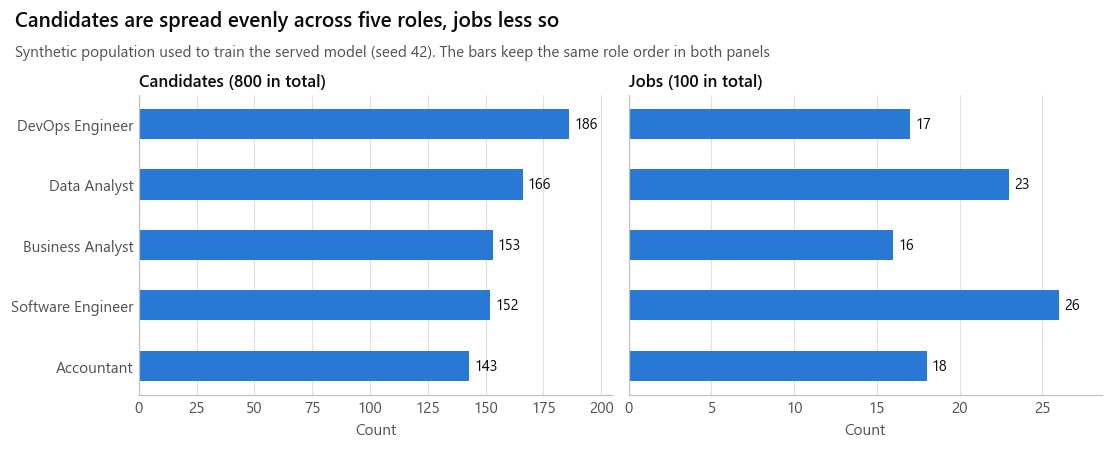

,candidates,jobs
target_role,,
DevOps Engineer,186,17
Data Analyst,166,23
Business Analyst,153,16
Software Engineer,152,26
Accountant,143,18


In [2]:
candidates = pd.DataFrame(snapshot["candidates"])
jobs = pd.DataFrame(snapshot["jobs"])
candidate_roles = candidates.target_role.value_counts()
job_roles = jobs.title.value_counts().reindex(candidate_roles.index).fillna(0).astype(int)

figure, axes = plt.subplots(1, 2, figsize=(10, 3.4), layout="constrained", sharey=True)
for axis, counts, label in ((axes[0], candidate_roles, f"Candidates ({len(candidates)} in total)"), (axes[1], job_roles, f"Jobs ({len(jobs)} in total)")):
    positions = np.arange(len(counts))[::-1]
    axis.barh(positions, counts.values, height=0.5, color=BLUE)
    axis.set_yticks(positions, counts.index)
    axis.set_title(label)
    bar_grid(axis)
    axis.spines["left"].set_color(AXIS)
    for position, value in zip(positions, counts.values):
        axis.text(value + counts.max() * 0.012, position, f"{value}", va="center", color=INK, fontsize=9.5)
    axis.set_xlim(0, counts.max() * 1.1)
    axis.set_xlabel("Count")
headed(figure, "Candidates are spread evenly across five roles, jobs less so", "Synthetic population used to train the served model (seed 42). The bars keep the same role order in both panels")
show(figure, "01_candidates_jobs_by_role")
display(pd.DataFrame({"candidates": candidate_roles, "jobs": job_roles}))

### Figure 2. Train, validation and test splits, with class balance

**Good matches outnumber non-matches by about 3 to 1.** This matters for every later figure: a model that always says yes would already score about 72% accuracy and 0.83 to 0.84 F1 on the test sets, so those are the numbers to beat, not 50%.

Splits are made by candidate, so nobody appears in two splits. The 18 cold-test jobs are also kept out of training and validation.

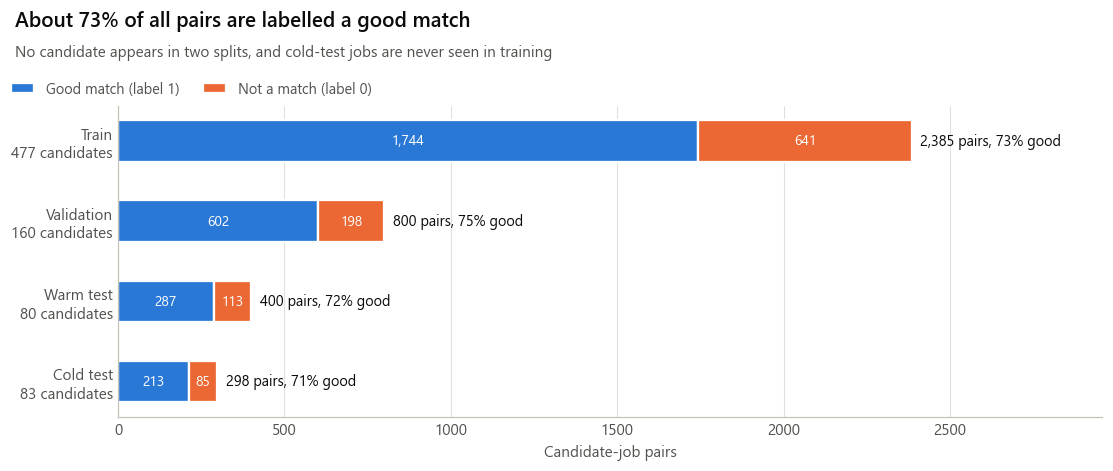

,pairs,good_match,not_a_match,good_match_rate,candidates,jobs_available
split,,,,,,
train,2385,1744,641,0.731237,477,82
validation,800,602,198,0.752500,160,82
warm_test,400,287,113,0.717500,80,82
cold_test,298,213,85,0.714765,83,18


In [3]:
candidate_groups, job_groups = manifest["candidate_groups"], manifest["job_groups"]
balance = pairs.groupby("split").label.agg(pairs="size", good_match="sum").reindex(SPLITS)
balance["not_a_match"] = balance.pairs - balance.good_match
balance["good_match_rate"] = balance.good_match / balance.pairs
balance["candidates"] = [len(candidate_groups[name]) for name in SPLITS]
balance["jobs_available"] = [len(job_groups["cold" if name == "cold_test" else "warm"]) for name in SPLITS]

figure, axis = plt.subplots(figsize=(10, 3.3), layout="constrained")
positions = np.arange(len(SPLITS))[::-1]
axis.barh(positions, balance.good_match, height=0.52, color=GOOD_COLOUR, edgecolor=SURFACE, linewidth=1.5, label="Good match (label 1)")
axis.barh(positions, balance.not_a_match, left=balance.good_match, height=0.52, color=NOT_COLOUR, edgecolor=SURFACE, linewidth=1.5, label="Not a match (label 0)")
axis.set_yticks(positions, [f"{SPLIT_NAMES[name]}\n{balance.candidates[name]} candidates" for name in SPLITS])
for position, name in zip(positions, SPLITS):
    row = balance.loc[name]
    axis.text(row.pairs + 25, position, f"{row.pairs:,.0f} pairs, {row.good_match_rate:.0%} good", va="center", color=INK, fontsize=9.5)
    axis.text(row.good_match / 2, position, f"{row.good_match:,.0f}", ha="center", va="center", color="white", fontsize=9)
    if row.not_a_match > 60:
        axis.text(row.good_match + row.not_a_match / 2, position, f"{row.not_a_match:,.0f}", ha="center", va="center", color="white", fontsize=9)
axis.set_xlim(0, balance.pairs.max() * 1.24)
axis.set_xlabel("Candidate-job pairs")
bar_grid(axis)
top_legend(figure, columns=2)
headed(figure, "About 73% of all pairs are labelled a good match", "No candidate appears in two splits, and cold-test jobs are never seen in training")
show(figure, "02_splits_and_class_balance")
display(balance)

### Figure 3. Experience, education and location

Candidate experience runs from 0 to 15 years (mean 7.7), while jobs ask for 0 to 8 years (mean 4.0). Candidates therefore often exceed the requirement, which explains the spike at 1.0 for experience readiness in Figure 5. Education and location are close to uniform, as a synthetic generator would produce, so they say nothing about the real Kenyan labour market.

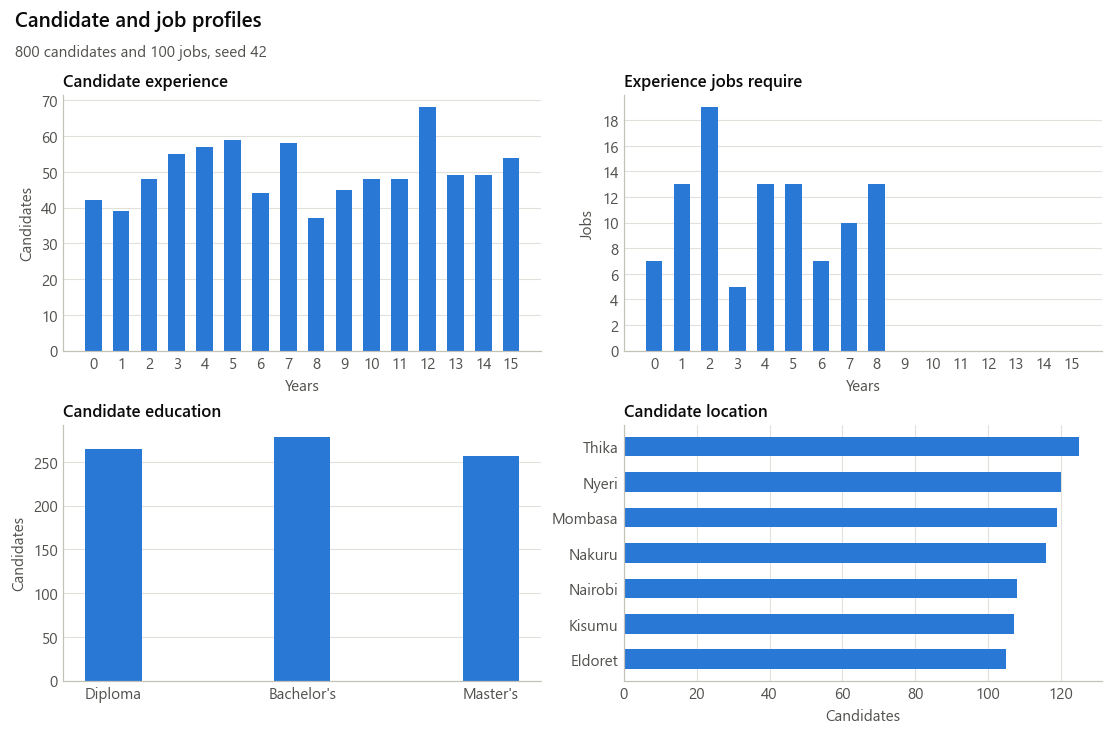

,count,mean,std,min,25%,50%,75%,max
candidates,800.0,7.69,4.57,0.0,4.0,7.0,12.0,15.0
jobs_required,100.0,3.99,2.56,0.0,2.0,4.0,6.0,8.0


In [4]:
figure, axes = plt.subplots(2, 2, figsize=(10, 6), layout="constrained")


def columns(axis, counts, title, xlabel=None):
    axis.bar(range(len(counts)), counts.values, width=0.6 if len(counts) > 5 else 0.3, color=BLUE)
    axis.set_xticks(range(len(counts)), counts.index)
    axis.set_title(title)
    bar_grid(axis, "y")
    if xlabel:
        axis.set_xlabel(xlabel)


years = range(0, int(max(candidates.years_experience.max(), jobs.required_experience_years.max())) + 1)
columns(axes[0, 0], candidates.years_experience.value_counts().reindex(years, fill_value=0), "Candidate experience", "Years")
columns(axes[0, 1], jobs.required_experience_years.value_counts().reindex(years, fill_value=0), "Experience jobs require", "Years")
columns(axes[1, 0], candidates.education.value_counts().reindex(["Diploma", "Bachelor's", "Master's"]), "Candidate education")
locations = candidates.location.value_counts()
positions = np.arange(len(locations))[::-1]
axes[1, 1].barh(positions, locations.values, height=0.55, color=BLUE)
axes[1, 1].set_yticks(positions, locations.index)
axes[1, 1].set_title("Candidate location")
bar_grid(axes[1, 1])
axes[0, 0].set_ylabel("Candidates")
axes[0, 1].set_ylabel("Jobs")
axes[0, 1].yaxis.set_major_locator(MaxNLocator(integer=True))
axes[1, 0].set_ylabel("Candidates")
axes[1, 1].set_xlabel("Candidates")
headed(figure, "Candidate and job profiles", f"{len(candidates)} candidates and {len(jobs)} jobs, seed 42")
show(figure, "03_profiles")
display(pd.DataFrame({"candidates": candidates.years_experience.describe().round(2), "jobs_required": jobs.required_experience_years.describe().round(2)}).T)

### Figure 4. Skills: what candidates list and what jobs ask for

SQL, Data Analysis, Python and Excel lead demand. Taxation and Financial Accounting appear because of the Accountant role noted under Figure 1. SQL has the largest gap in points (47% of jobs against 29% of candidates), and Git the largest in proportion (20% against 9%).

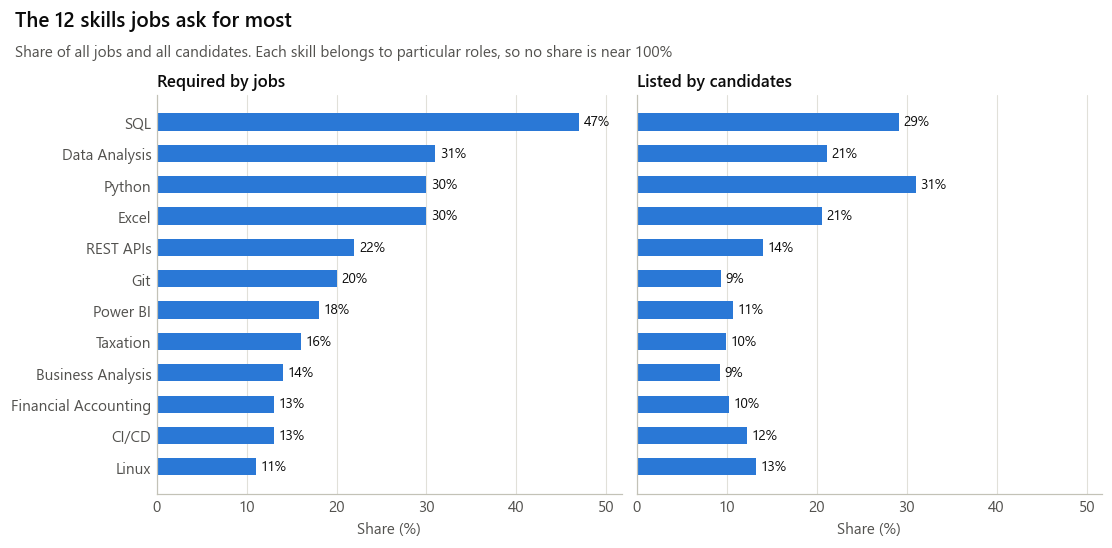

,required_by_jobs_pct,listed_by_candidates_pct
SQL,47.0,29.1
Data Analysis,31.0,21.1
Python,30.0,31.0
Excel,30.0,20.6
REST APIs,22.0,14.0
Git,20.0,9.4
Power BI,18.0,10.8
Taxation,16.0,9.9
Business Analysis,14.0,9.2
Financial Accounting,13.0,10.2


In [5]:
listed = Counter(skill for skills in candidates.skills for skill in skills)
required = Counter(skill for skills in jobs.required_skills for skill in skills)
top = [skill for skill, _ in required.most_common(12)]
skills = pd.DataFrame({
    "required_by_jobs_pct": [100 * required[skill] / len(jobs) for skill in top],
    "listed_by_candidates_pct": [100 * listed[skill] / len(candidates) for skill in top],
}, index=top)

figure, axes = plt.subplots(1, 2, figsize=(10, 4.3), layout="constrained", sharey=True)
positions = np.arange(len(top))[::-1]
for axis, column, title in ((axes[0], "required_by_jobs_pct", "Required by jobs"), (axes[1], "listed_by_candidates_pct", "Listed by candidates")):
    axis.barh(positions, skills[column], height=0.55, color=BLUE)
    axis.set_yticks(positions, top)
    axis.set_title(title)
    axis.set_xlabel("Share (%)")
    axis.set_xlim(0, max(skills.max().max() * 1.1, 1))
    bar_grid(axis)
    for position, value in zip(positions, skills[column]):
        axis.text(value + 0.5, position, f"{value:.0f}%", va="center", color=INK, fontsize=9)
headed(figure, f"The {len(top)} skills jobs ask for most", "Share of all jobs and all candidates. Each skill belongs to particular roles, so no share is near 100%")
show(figure, "04_top_skills")
display(skills.round(1))

### Figure 5. The three model inputs, by label

Good matches score higher on average on all three inputs: semantic 0.64 against 0.57, related-skill overlap 0.91 against 0.83, experience readiness 0.85 against 0.59. Experience readiness separates the classes most, which fits its top weight in Figure 8. The inputs are almost uncorrelated (all within 0.05 of zero, see the second table), so each adds separate information.

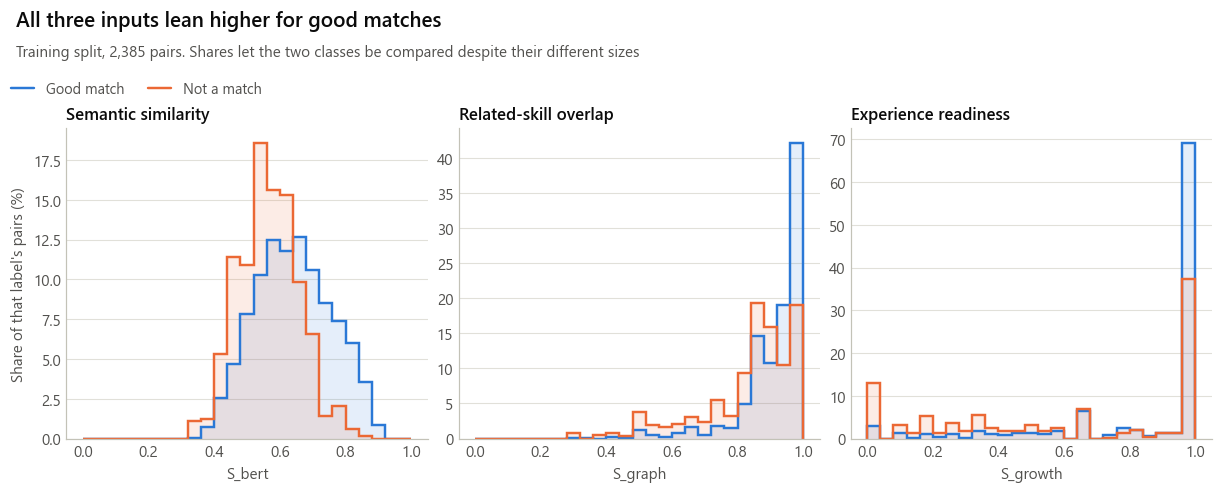

,S_bert,S_graph,S_growth
label,,,
"mean, not a match",0.567,0.834,0.593
"mean, good match",0.641,0.914,0.854


,S_bert,S_graph,S_growth
S_bert,1.00,0.05,0.05
S_graph,0.05,1.00,-0.04
S_growth,0.05,-0.04,1.00


In [6]:
train = pairs[pairs.split == "train"]
figure, axes = plt.subplots(1, 3, figsize=(11, 3.5), layout="constrained")
for axis, (column, title) in zip(axes, FEATURES.items()):
    edges = np.linspace(0, 1, 26)
    for label, colour, name in ((1, GOOD_COLOUR, "Good match"), (0, NOT_COLOUR, "Not a match")):
        values = train.loc[train.label == label, column]
        axis.hist(values, bins=edges, weights=np.full(len(values), 100 / len(values)), histtype="stepfilled", color=colour, alpha=0.12)
        axis.hist(values, bins=edges, weights=np.full(len(values), 100 / len(values)), histtype="step", color=colour, linewidth=1.6, label=name)
    axis.set_title(title.split(" (")[0])
    axis.set_xlabel(title.split("(")[1].rstrip(")"))
    bar_grid(axis, "y")
axes[0].set_ylabel("Share of that label's pairs (%)")
handles = [Line2D([], [], color=GOOD_COLOUR, label="Good match"), Line2D([], [], color=NOT_COLOUR, label="Not a match")]
top_legend(figure, handles, [item.get_label() for item in handles], 2)
headed(figure, "All three inputs lean higher for good matches", f"Training split, {len(train):,} pairs. Shares let the two classes be compared despite their different sizes")
show(figure, "05_features_by_label")
summary = train.groupby("label")[list(FEATURES)].mean().round(3).rename(index={0: "mean, not a match", 1: "mean, good match"})
display(summary)
display(train[list(FEATURES)].corr().round(2))

---
# Part 2. Training

### Figure 6. Training and validation loss

**There is no sign of overfitting, and also no learning curve to speak of.** Training loss sits between 0.430 and 0.433 from the first epoch to the last, and validation loss between 0.429 and 0.446. The model has only four parameters (three weights and an intercept), so one pass over 2,385 pairs is enough for it to settle. The later movement is noise from the constant learning rate.

**Epoch 4 is the lowest point of that noise, not a clear optimum.** Epoch 4 was chosen by the lowest validation loss, which is the correct rule, but it should not be read as a meaningfully better state than its neighbours. It is also why validation loss briefly falls below training loss there (gap of -0.0036). The usual gap is about +0.005.

The y-axis is zoomed in heavily. On an axis starting at 0 the two lines would look almost identical.

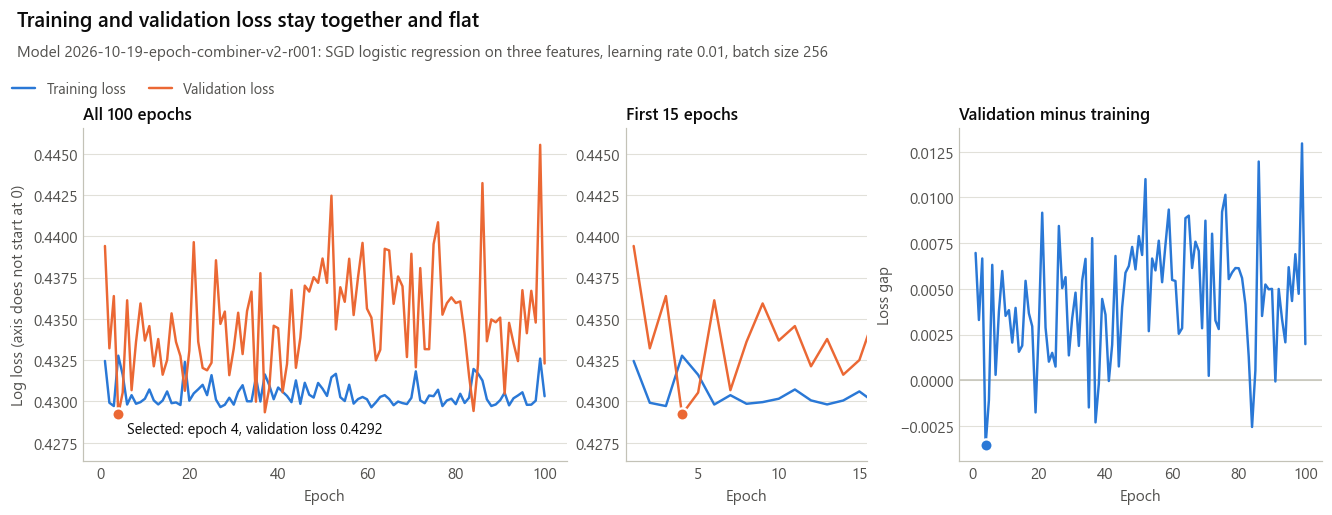

,train_loss,validation_loss,gap
min,0.4296,0.4292,-0.0036
median,0.4302,0.4348,0.0049
max,0.4328,0.4455,0.0130


,train_loss,validation_loss,gap
epoch,,,
1,0.4325,0.4394,0.0070
2,0.4299,0.4332,0.0033
3,0.4297,0.4364,0.0067
4,0.4328,0.4292,-0.0036
5,0.4316,0.4305,-0.0011
10,0.4302,0.4337,0.0035
25,0.4316,0.4323,0.0008
50,0.4308,0.4387,0.0079
75,0.4303,0.4395,0.0092


In [7]:
def load_history(run):
    rows = []
    for folder in sorted((run / "epochs").iterdir()):
        record = json.loads((folder / "epoch.json").read_text(encoding="utf-8"))
        state = json.loads((folder / "checkpoint.bin").read_bytes())
        rows.append({
            "epoch": record["epoch"], "train_loss": record["train_loss"], "validation_loss": record["validation_loss"],
            "recorded_validation_auc": record["validation_metrics"]["roc_auc"], "recorded_threshold": record["validation_metrics"]["threshold"],
            "intercept": state["intercept"][0], **dict(zip(FEATURES, state["coefficients"][0])), "scaler_mean": state["scaler_mean"], "scaler_scale": state["scaler_scale"],
        })
    return pd.DataFrame(rows).set_index("epoch")


history = load_history(RUN_V2)
history["gap"] = history.validation_loss - history.train_loss
SELECTED = recorded["selected_epoch"]
assert history.validation_loss.idxmin() == SELECTED

figure, axes = plt.subplots(1, 3, figsize=(12, 3.7), layout="constrained", gridspec_kw={"width_ratios": [2, 1, 1.5]})
for axis in axes[:2]:
    axis.plot(history.index, history.train_loss, color=TRAIN_COLOUR, label="Training loss")
    axis.plot(history.index, history.validation_loss, color=VALIDATION_COLOUR, label="Validation loss")
    axis.plot(SELECTED, history.validation_loss[SELECTED], "o", color=VALIDATION_COLOUR, markersize=8, markeredgecolor=SURFACE, markeredgewidth=1.5, zorder=5)
    axis.set_xlabel("Epoch")
    axis.set_ylim(min(history.train_loss.min(), history.validation_loss.min()) - 0.0028, max(history.train_loss.max(), history.validation_loss.max()) + 0.001)
    axis.grid(True, axis="y")
axes[0].set_title("All 100 epochs")
axes[0].set_ylabel("Log loss (axis does not start at 0)")
axes[0].text(SELECTED + 2, history.validation_loss[SELECTED] - 0.0009, f"Selected: epoch {SELECTED}, validation loss {history.validation_loss[SELECTED]:.4f}", color=INK, fontsize=9.5, va="center")
axes[1].set_title("First 15 epochs")
axes[1].set_xlim(0.5, 15.5)
axes[2].axhline(0, color=AXIS, linewidth=1)
axes[2].plot(history.index, history.gap, color=BLUE)
axes[2].plot(SELECTED, history.gap[SELECTED], "o", color=BLUE, markersize=8, markeredgecolor=SURFACE, markeredgewidth=1.5, zorder=5)
axes[2].set_title("Validation minus training")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Loss gap")
axes[2].grid(True, axis="y")
top_legend(figure, columns=2)
headed(figure, "Training and validation loss stay together and flat", f"Model {model_v2['model_version']}: SGD logistic regression on three features, learning rate 0.01, batch size 256")
show(figure, "06_training_validation_loss")
history[["train_loss", "validation_loss", "gap", "S_bert", "S_graph", "S_growth", "intercept"]].to_csv(FIGURES / "epoch_history.csv")
display(history[["train_loss", "validation_loss", "gap"]].agg(["min", "median", "max"]).round(4))
display(history.loc[[1, 2, 3, 4, 5, 10, 25, 50, 75, 100], ["train_loss", "validation_loss", "gap"]].round(4))

### Figure 7. Training and validation metrics by epoch

Training and validation stay close on every metric, which supports the no-overfitting reading: ROC-AUC is 0.835 on training and 0.818 on validation at epoch 4. Validation F1 and precision run slightly above training only because validation has more positives (75% against 73%). Each panel has its own zoomed y-axis, so the jagged lines are small movements.

These use the 0.50 threshold the trainer records every epoch, so the epoch 4 values differ from Figure 9, which uses the final 0.46 threshold.

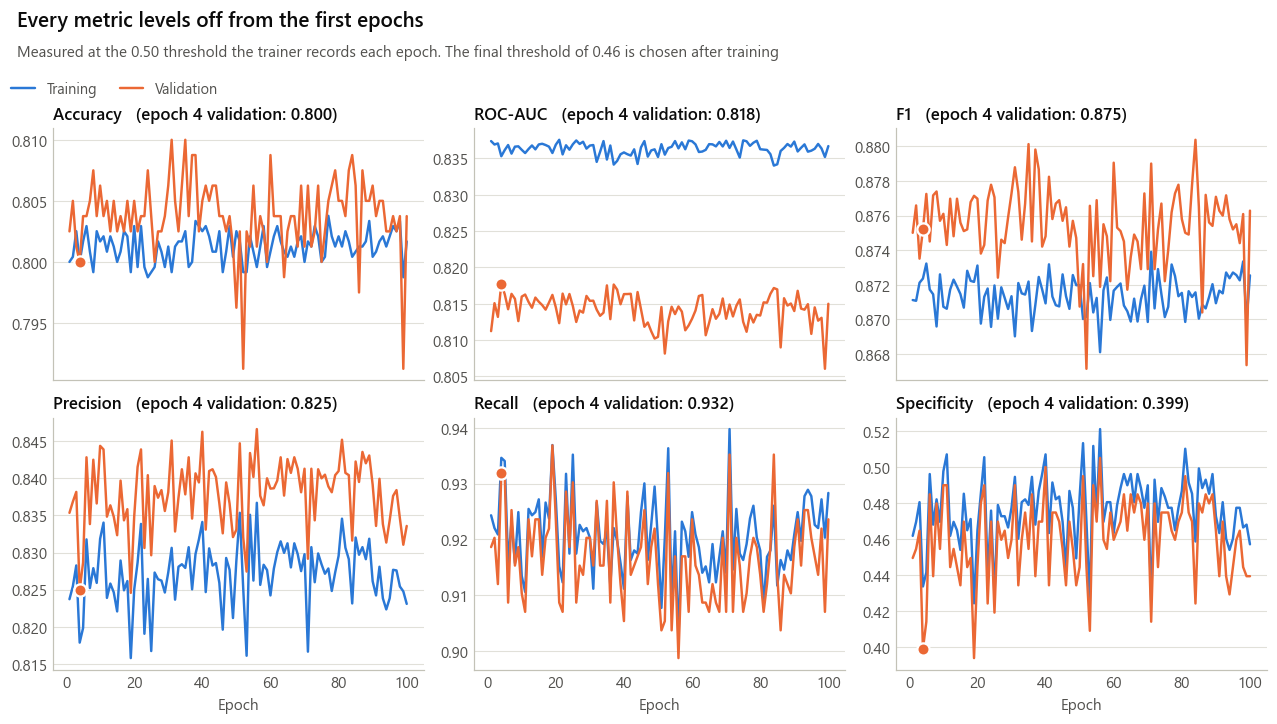

accuracy            roc_auc                f1            precision  \
split    train validation   train validation  train validation     train   
epoch                                                                      
1        0.800      0.802   0.837      0.811  0.871      0.875     0.824   
4        0.800      0.800   0.835      0.818  0.872      0.875     0.818   
100      0.802      0.804   0.837      0.815  0.873      0.876     0.823   

                 recall            specificity             
split validation  train validation       train validation  
epoch                                                      
1          0.835  0.924      0.919       0.462      0.449  
4          0.825  0.935      0.932       0.434      0.399  
100        0.834  0.928      0.924       0.457      0.439

In [8]:
features = pairs[list(FEATURES)].to_numpy()
EPOCH_THRESHOLD = 0.5
rows = []
for epoch, row in history.iterrows():
    state = {"scaler_mean": row.scaler_mean, "scaler_scale": row.scaler_scale, "logistic_regression": {"intercept": row.intercept, "coefficients": [row.S_bert, row.S_graph, row.S_growth]}}
    scores = sigmoid_score(state, features)
    for split in ("train", "validation"):
        mask = (pairs.split == split).to_numpy()
        labels = pairs.label.to_numpy()[mask]
        rows.append({"epoch": epoch, "split": split, "roc_auc": auc(labels, scores[mask]), **at_threshold(labels, scores[mask], EPOCH_THRESHOLD)})
epoch_metrics = pd.DataFrame(rows)
validation_by_epoch = epoch_metrics[epoch_metrics.split == "validation"].set_index("epoch")
assert np.allclose(validation_by_epoch.roc_auc, history.recorded_validation_auc, atol=1e-6), "recomputed validation AUC differs from the epoch records"

panels = {"accuracy": "Accuracy", "roc_auc": "ROC-AUC", "f1": "F1", "precision": "Precision", "recall": "Recall", "specificity": "Specificity"}
figure, axes = plt.subplots(2, 3, figsize=(11.5, 5.6), layout="constrained", sharex=True)
for axis, (metric, title) in zip(axes.flat, panels.items()):
    for split, colour, label in (("train", TRAIN_COLOUR, "Training"), ("validation", VALIDATION_COLOUR, "Validation")):
        series = epoch_metrics[epoch_metrics.split == split].set_index("epoch")[metric]
        axis.plot(series.index, series, color=colour, label=label)
    value = validation_by_epoch[metric][SELECTED]
    axis.plot(SELECTED, value, "o", color=VALIDATION_COLOUR, markersize=8, markeredgecolor=SURFACE, markeredgewidth=1.5, zorder=5)
    axis.set_title(f"{title}   (epoch {SELECTED} validation: {value:.3f})")
    axis.grid(True, axis="y")
for axis in axes[1]:
    axis.set_xlabel("Epoch")
top_legend(figure, columns=2)
headed(figure, "Every metric levels off from the first epochs", f"Measured at the 0.50 threshold the trainer records each epoch. The final threshold of {THRESHOLD:.2f} is chosen after training")
show(figure, "07_metrics_by_epoch")
table = epoch_metrics[epoch_metrics.epoch.isin([1, SELECTED, 100])].pivot(index="epoch", columns="split", values=list(panels)).round(3)
display(table)

### Figure 8. Model weights over training

A one standard deviation rise in experience readiness multiplies the odds of a good match by about 2.6, against about 2.0 for each of the other two inputs. **Read the order with care:** the weights keep moving between epochs by more than the 0.03 that separates semantic similarity from related-skill overlap, and those two swap places repeatedly. Only experience readiness staying highest for most of the run is a fairly stable finding.

These weights describe what the synthetic labels reward, not what real recruiters value.

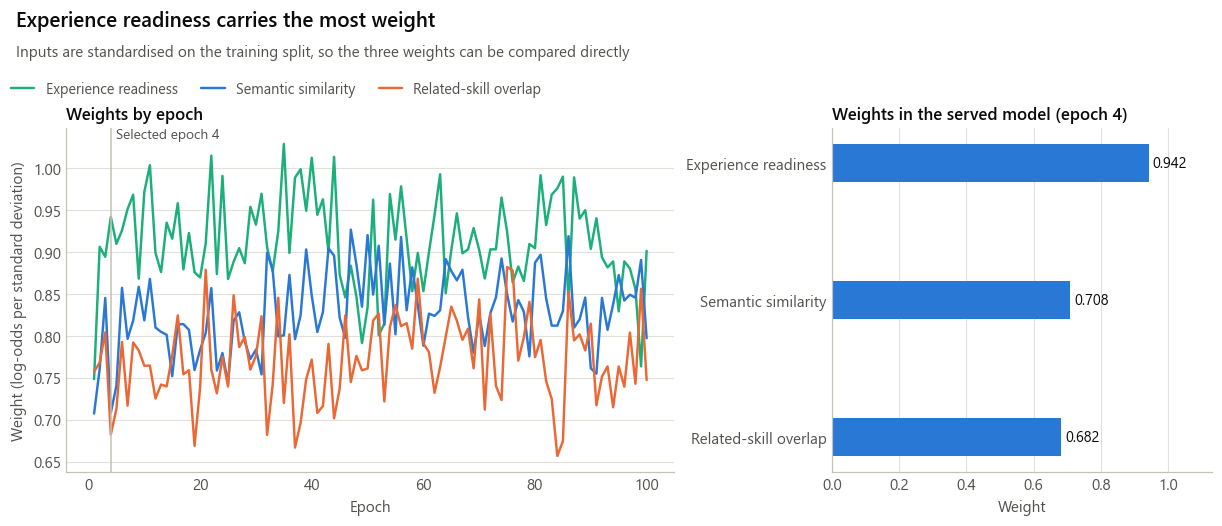

,S_bert,S_graph,S_growth,intercept
epoch,,,,
1,0.707,0.757,0.748,1.236
4,0.708,0.682,0.942,1.463
100,0.797,0.747,0.901,1.432


,S_bert,S_graph,S_growth,intercept
min,0.707,0.657,0.748,1.236
median,0.826,0.769,0.904,1.358
max,0.926,0.882,1.029,1.484


Odds multiplier for a one standard deviation rise: {'S_graph': 1.98, 'S_bert': 2.03, 'S_growth': 2.56}


In [9]:
figure, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained", gridspec_kw={"width_ratios": [1.6, 1]})
axis = axes[0]
paths = {"S_growth": (AQUA, "Experience readiness"), "S_bert": (BLUE, "Semantic similarity"), "S_graph": (ORANGE, "Related-skill overlap")}
for column, (colour, label) in paths.items():
    axis.plot(history.index, history[column], color=colour, label=label)
axis.axvline(SELECTED, color=AXIS, linewidth=1)
axis.text(SELECTED + 1, axis.get_ylim()[1], f"Selected epoch {SELECTED}", color=INK_2, fontsize=9, va="top")
axis.set_xlabel("Epoch")
axis.set_ylabel("Weight (log-odds per standard deviation)")
axis.set_title("Weights by epoch")
axis.grid(True, axis="y")
top_legend(figure, columns=3)

axis = axes[1]
weights = pd.Series(dict(zip(FEATURES, model_v2["logistic_regression"]["coefficients"]))).sort_values()
axis.barh(range(3), weights.values, height=0.28, color=BLUE)
axis.set_yticks(range(3), [FEATURES[name].split(" (")[0] for name in weights.index])
for position, value in enumerate(weights.values):
    axis.text(value + 0.012, position, f"{value:.3f}", va="center", color=INK, fontsize=9.5)
axis.set_xlim(0, weights.max() * 1.2)
axis.set_title(f"Weights in the served model (epoch {SELECTED})")
axis.set_xlabel("Weight")
bar_grid(axis)
headed(figure, "Experience readiness carries the most weight", "Inputs are standardised on the training split, so the three weights can be compared directly")
show(figure, "08_model_weights")
display(history.loc[[1, SELECTED, 100], ["S_bert", "S_graph", "S_growth", "intercept"]].round(3))
display(history[["S_bert", "S_graph", "S_growth", "intercept"]].agg(["min", "median", "max"]).round(3))
print("Odds multiplier for a one standard deviation rise:", {name: round(float(np.exp(value)), 2) for name, value in weights.items()})

---
# Part 3. Evaluation

### Figure 9. Confusion matrices

**This is the most important figure for honest reporting.** The model catches almost every good match (recall 95% warm, 99% cold) but rejects only 42% of warm non-matches and 31% of cold ones. In the cold test, 59 of 85 non-matches are labelled a good match.

Overall accuracy of about 80% looks reasonable, but always saying yes would already get about 72%. Balanced accuracy, 0.68 warm and 0.65 cold, is the fairer summary. The cause is the threshold rule: choosing the highest F1 on data that is 75% positive favours saying yes, as Figure 15 shows.

The model ranks candidates better than this yes/no line suggests, so ROC, ranking and calibration (Figures 11, 13 and 16) should be read alongside it.

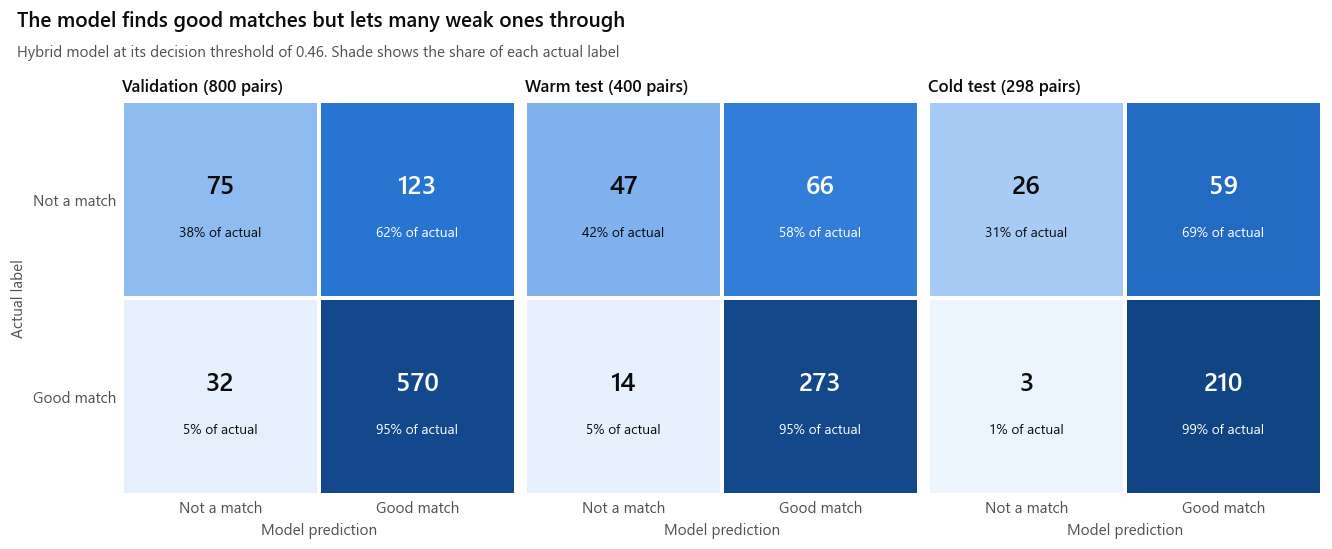

,tn,fp,fn,tp,accuracy,precision,recall,specificity,f1,balanced_accuracy
Validation,75.0,123.0,32.0,570.0,0.806,0.823,0.947,0.379,0.880,0.663
Warm test,47.0,66.0,14.0,273.0,0.800,0.805,0.951,0.416,0.872,0.684
Cold test,26.0,59.0,3.0,210.0,0.792,0.781,0.986,0.306,0.871,0.646


In [10]:
def confusion_panel(axis, labels, scores, threshold, title, ylabels=True):
    result = at_threshold(labels, scores, threshold)
    counts = np.array([[result["tn"], result["fp"]], [result["fn"], result["tp"]]])
    shares = counts / counts.sum(axis=1, keepdims=True)
    axis.pcolormesh(shares[::-1], cmap=SEQUENTIAL, vmin=0, vmax=1, edgecolors=SURFACE, linewidth=2.5)
    for row in range(2):
        for column in range(2):
            ink = "white" if shares[row, column] > 0.5 else INK
            axis.text(column + 0.5, 1.56 - row, f"{counts[row, column]}", ha="center", va="center", fontsize=17, fontweight="semibold", color=ink)
            axis.text(column + 0.5, 1.33 - row, f"{shares[row, column]:.0%} of actual", ha="center", va="center", fontsize=9, color=ink)
    axis.set_xticks([0.5, 1.5], ["Not a match", "Good match"])
    axis.set_yticks([1.5, 0.5], ["Not a match", "Good match"] if ylabels else ["", ""])
    axis.set_xlabel("Model prediction")
    if ylabels:
        axis.set_ylabel("Actual label")
    axis.set_title(title)
    axis.set_aspect("equal")
    for spine in axis.spines.values():
        spine.set_visible(False)
    return result


figure, axes = plt.subplots(1, 3, figsize=(12, 4.3), layout="constrained")
rows = {}
for index, (axis, split) in enumerate(zip(axes, ("validation", "warm_test", "cold_test"))):
    part = pairs[pairs.split == split]
    rows[SPLIT_NAMES[split]] = confusion_panel(axis, part.label, part.hybrid, THRESHOLD, f"{SPLIT_NAMES[split]} ({len(part)} pairs)", index == 0)
headed(figure, "The model finds good matches but lets many weak ones through", f"Hybrid model at its decision threshold of {THRESHOLD:.2f}. Shade shows the share of each actual label")
show(figure, "09_confusion_matrices")
display(pd.DataFrame(rows).T[["tn", "fp", "fn", "tp", "accuracy", "precision", "recall", "specificity", "f1", "balanced_accuracy"]].round(3))

### Table: all test metrics with confidence intervals

Point results with 95% bootstrap intervals. The second table tests the differences directly, using the same resamples for both models. Intervals resample candidates only, so they do not capture uncertainty from the small number of jobs (18 in the cold test) and are, if anything, too narrow.

Log loss and Brier are shown for the hybrid model only. The baselines' scores are not probabilities, so those measures would not be a fair comparison.

In [11]:
def full_metrics(part, name, threshold):
    labels, scores = part.label.to_numpy(), part[name].to_numpy()
    result = at_threshold(labels, scores, threshold)
    result.update(roc_auc=auc(labels, scores), average_precision=average_precision_score(labels, scores), threshold=threshold, pairs=len(labels))
    if name == "hybrid":
        result.update(log_loss=log_loss(labels, scores), brier=brier_score_loss(labels, scores))
    return result


def bootstrap(part, resamples=1000):
    """Resample whole candidates, because one candidate's pairs are not independent of each other."""
    rows_by_candidate = list(part.reset_index(drop=True).groupby("candidate_id").indices.values())
    labels = part.label.to_numpy()
    scores = {name: part[name].to_numpy() for name in MODELS}
    outcomes = {name: {metric: [] for metric in ("roc_auc", "f1", "specificity", "accuracy")} for name in MODELS}
    for _ in range(resamples):
        chosen = np.concatenate([rows_by_candidate[index] for index in RANDOM.integers(len(rows_by_candidate), size=len(rows_by_candidate))])
        for name in MODELS:
            result = at_threshold(labels[chosen], scores[name][chosen], THRESHOLDS[name])
            outcomes[name]["roc_auc"].append(auc(labels[chosen], scores[name][chosen]))
            for metric in ("f1", "specificity", "accuracy"):
                outcomes[name][metric].append(result[metric])
    return outcomes


TEST_SPLITS = ("warm_test", "cold_test")
parts = {split: pairs[pairs.split == split] for split in TEST_SPLITS}
points = {split: {name: full_metrics(parts[split], name, THRESHOLDS[name]) for name in MODELS} for split in TEST_SPLITS}
intervals = {split: bootstrap(parts[split]) for split in TEST_SPLITS}
always_yes = {split: {"accuracy": parts[split].label.mean(), "f1": 2 * parts[split].label.mean() / (1 + parts[split].label.mean()), "specificity": 0.0, "roc_auc": 0.5} for split in TEST_SPLITS}

records = []
for split in TEST_SPLITS:
    for name, (label, _, _) in MODELS.items():
        record = {"split": SPLIT_NAMES[split], "model": label, **points[split][name]}
        for metric, values in intervals[split][name].items():
            record[f"{metric}_low"], record[f"{metric}_high"] = np.percentile(values, [2.5, 97.5])
        records.append(record)
    records.append({"split": SPLIT_NAMES[split], "model": "Always say yes", "pairs": len(parts[split]), **always_yes[split]})
metrics_table = pd.DataFrame(records)
metrics_table.to_csv(FIGURES / "test_metrics.csv", index=False)
display(metrics_table[["split", "model", "threshold", "accuracy", "precision", "recall", "specificity", "f1", "balanced_accuracy", "roc_auc", "average_precision", "log_loss", "brier"]].round(3))

differences = []
for split in TEST_SPLITS:
    for rival in ("fixed_weights", "semantic_only"):
        for metric in ("roc_auc", "f1", "accuracy"):
            gap = np.array(intervals[split]["hybrid"][metric]) - np.array(intervals[split][rival][metric])
            low, high = np.percentile(gap, [2.5, 97.5])
            differences.append({"split": SPLIT_NAMES[split], "hybrid minus": MODELS[rival][0], "metric": metric, "difference": points[split]["hybrid"][metric] - points[split][rival][metric], "low": low, "high": high, "interval excludes 0": bool(low > 0 or high < 0)})
differences = pd.DataFrame(differences)
display(differences.round(3))

,split,model,threshold,accuracy,precision,recall,specificity,f1,balanced_accuracy,roc_auc,average_precision,log_loss,brier
0,Warm test,Hybrid model,0.46,0.800,0.805,0.951,0.416,0.872,0.684,0.807,0.902,0.459,0.147
1,Warm test,Fixed weights,0.66,0.792,0.805,0.937,0.425,0.866,0.681,0.803,0.902,NaN,NaN
2,Warm test,Semantic only,0.05,0.718,0.718,1.000,0.000,0.836,0.500,0.625,0.831,NaN,NaN
3,Warm test,Always say yes,NaN,0.718,NaN,NaN,0.000,0.836,NaN,0.500,NaN,NaN,NaN
4,Cold test,Hybrid model,0.46,0.792,0.781,0.986,0.306,0.871,0.646,0.847,0.928,0.435,0.141
5,Cold test,Fixed weights,0.66,0.782,0.774,0.981,0.282,0.865,0.632,0.853,0.932,NaN,NaN
6,Cold test,Semantic only,0.05,0.715,0.715,1.000,0.000,0.834,0.500,0.728,0.884,NaN,NaN
7,Cold test,Always say yes,NaN,0.715,NaN,NaN,0.000,0.834,NaN,0.500,NaN,NaN,NaN


,split,hybrid minus,metric,difference,low,high,interval excludes 0
0,Warm test,Fixed weights,roc_auc,0.004,-0.005,0.014,False
1,Warm test,Fixed weights,f1,0.006,-0.008,0.020,False
2,Warm test,Fixed weights,accuracy,0.008,-0.015,0.030,False
3,Warm test,Semantic only,roc_auc,0.182,0.121,0.236,True
4,Warm test,Semantic only,f1,0.037,0.006,0.069,True
5,Warm test,Semantic only,accuracy,0.083,0.030,0.140,True
6,Cold test,Fixed weights,roc_auc,-0.005,-0.014,0.004,False
7,Cold test,Fixed weights,f1,0.006,-0.001,0.015,False
8,Cold test,Fixed weights,accuracy,0.010,0.000,0.023,False
9,Cold test,Semantic only,roc_auc,0.120,0.061,0.182,True


### Figure 10. The hybrid model against its baselines

**Hybrid against semantic-only: a clear win.** The ROC-AUC gain is 0.18 warm and 0.12 cold, and the intervals exclude zero. Semantic-only's best threshold is 0.05, which means it accepts everyone, so it lands exactly on the always-yes F1 and accuracy.

**Hybrid against fixed weights: no demonstrated difference.** ROC-AUC differs by +0.004 warm and -0.005 cold, F1 by +0.006 in both, and every interval includes zero. The roadmap's statement that the hybrid wins F1 on every split is true of the point values, but the gap is within noise. The learned model's practical advantage over the hand-set 0.45/0.40/0.15 weights is that its scores are calibrated probabilities (Figure 13), and the fixed weights were themselves well chosen.

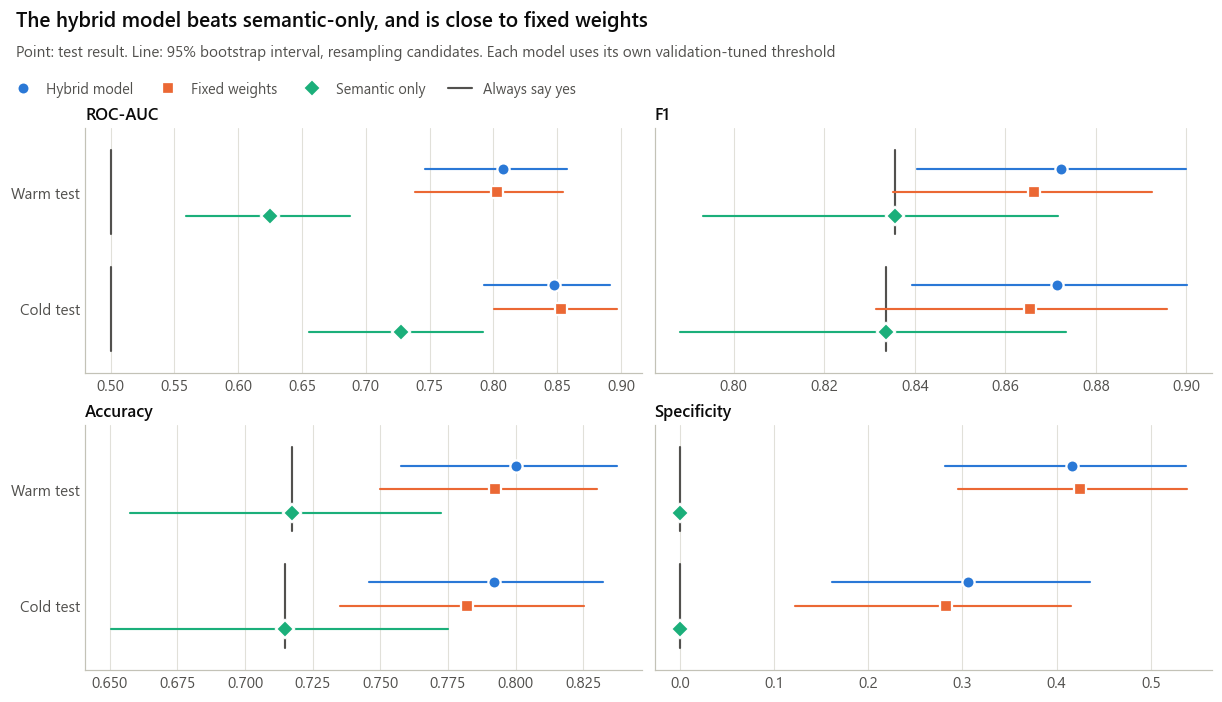

roc_auc                  f1            accuracy            \
split          Cold test Warm test Cold test Warm test Cold test Warm test   
model                                                                        
Always say yes     0.500     0.500     0.834     0.836     0.715     0.718   
Fixed weights      0.853     0.803     0.865     0.866     0.782     0.792   
Hybrid model       0.847     0.807     0.871     0.872     0.792     0.800   
Semantic only      0.728     0.625     0.834     0.836     0.715     0.718   

               specificity            
split            Cold test Warm test  
model                                 
Always say yes       0.000     0.000  
Fixed weights        0.282     0.425  
Hybrid model         0.306     0.416  
Semantic only        0.000     0.000

In [12]:
panels = {"roc_auc": "ROC-AUC", "f1": "F1", "accuracy": "Accuracy", "specificity": "Specificity"}
figure, axes = plt.subplots(2, 2, figsize=(11, 5.4), layout="constrained", sharey=True)
offsets = {"hybrid": 0.2, "fixed_weights": 0, "semantic_only": -0.2}
for axis, (metric, title) in zip(axes.flat, panels.items()):
    for row, split in enumerate(TEST_SPLITS):
        base = 1 - row
        for name, (label, colour, marker) in MODELS.items():
            low, high = np.percentile(intervals[split][name][metric], [2.5, 97.5])
            value = points[split][name][metric]
            axis.plot([low, high], [base + offsets[name]] * 2, color=colour, linewidth=1.4, zorder=2)
            axis.plot(value, base + offsets[name], marker, color=colour, markersize=8, markeredgecolor=SURFACE, markeredgewidth=1.5, zorder=3, label=label)
        reference = always_yes[split][metric]
        axis.plot([reference, reference], [base - 0.36, base + 0.36], color=INK_2, linewidth=1.4, zorder=1, label="Always say yes")
    axis.set_yticks([1, 0], [SPLIT_NAMES[split] for split in TEST_SPLITS])
    axis.set_ylim(-0.55, 1.55)
    axis.set_title(title)
    axis.grid(True, axis="x")
    axis.set_axisbelow(True)
handles, labels = axes[0, 0].get_legend_handles_labels()
unique = dict(zip(labels, handles))
top_legend(figure, list(unique.values()), list(unique), 4)
headed(figure, "The hybrid model beats semantic-only, and is close to fixed weights", "Point: test result. Line: 95% bootstrap interval, resampling candidates. Each model uses its own validation-tuned threshold")
show(figure, "10_baseline_comparison")
display(metrics_table.pivot(index="model", columns="split", values=list(panels)).round(3))

### Figure 11. ROC curves

ROC-AUC is 0.807 warm and 0.847 cold for the hybrid model, against 0.625 and 0.728 for semantic-only. The hybrid and fixed-weight curves cross repeatedly, which matches Figure 10. The cold test scores higher than the warm test here, so unseen jobs did not hurt ranking. Figure 18 shows this order reverses on a fresh population, so treat the gap between warm and cold as sampling variation.

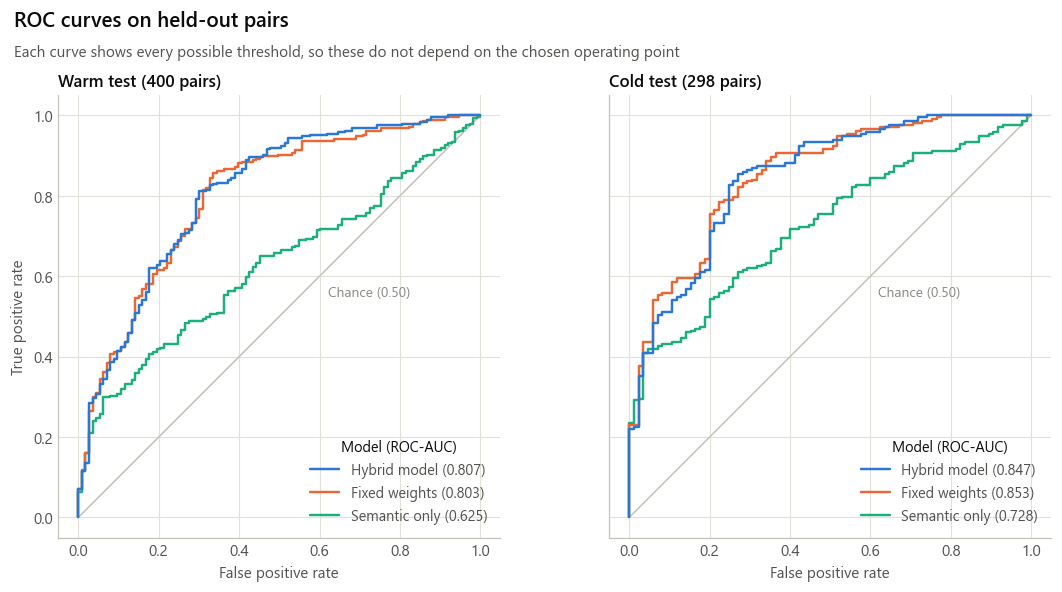

roc_auc           roc_auc_low           roc_auc_high          
split         Cold test Warm test   Cold test Warm test    Cold test Warm test
model                                                                         
Fixed weights     0.853     0.803       0.800     0.739        0.897     0.854
Hybrid model      0.847     0.807       0.793     0.746        0.891     0.857
Semantic only     0.728     0.625       0.655     0.559        0.792     0.687

In [13]:
figure, axes = plt.subplots(1, 2, figsize=(10, 4.7), layout="constrained", sharey=True)
for axis, split in zip(axes, TEST_SPLITS):
    part = parts[split]
    axis.plot([0, 1], [0, 1], color=AXIS, linewidth=1)
    axis.text(0.62, 0.55, "Chance (0.50)", color=MUTED, fontsize=9, rotation=0)
    for name, (label, colour, _) in reversed(list(MODELS.items())):
        fpr, tpr, _ = roc_curve(part.label, part[name])
        axis.plot(fpr, tpr, color=colour, label=f"{label} ({points[split][name]['roc_auc']:.3f})")
    handles, labels = axis.get_legend_handles_labels()
    axis.legend(handles[::-1], labels[::-1], loc="lower right", title="Model (ROC-AUC)", title_fontsize=9.5)
    axis.set_title(f"{SPLIT_NAMES[split]} ({len(part)} pairs)")
    axis.set_xlabel("False positive rate")
    axis.set_aspect("equal")
    axis.grid(True)
    axis.set_axisbelow(True)
axes[0].set_ylabel("True positive rate")
headed(figure, "ROC curves on held-out pairs", "Each curve shows every possible threshold, so these do not depend on the chosen operating point")
show(figure, "11_roc_curves")
display(metrics_table[metrics_table.model != "Always say yes"].pivot(index="model", columns="split", values=["roc_auc", "roc_auc_low", "roc_auc_high"]).round(3))

### Figure 12. Precision-recall curves

Precision stays above 0.85 until recall passes about 0.8, then drops as the threshold lowers. The current threshold (the dot) sits low on that curve, near the point where the model accepts nearly everyone. Moving left along the curve trades missed matches for a cleaner shortlist. Average precision is 0.902 warm and 0.928 cold, measured against a floor of about 0.72.

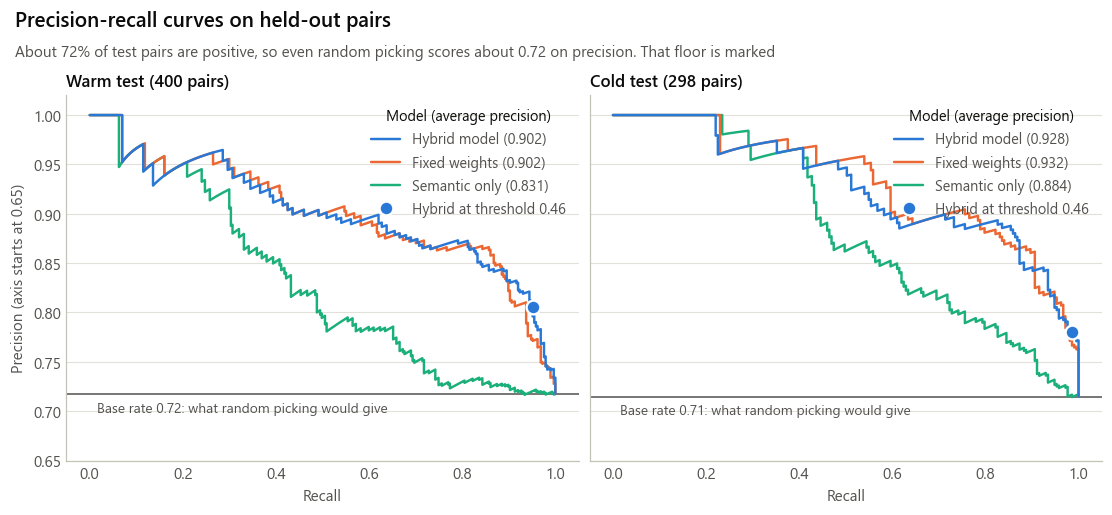

split,Cold test,Warm test
model,,
Fixed weights,0.932,0.902
Hybrid model,0.928,0.902
Semantic only,0.884,0.831


In [14]:
figure, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained", sharey=True)
for axis, split in zip(axes, TEST_SPLITS):
    part = parts[split]
    rate = part.label.mean()
    axis.axhline(rate, color=INK_2, linewidth=1)
    axis.text(0.015, rate - 0.008, f"Base rate {rate:.2f}: what random picking would give", color=INK_2, fontsize=9, va="top")
    for name, (label, colour, _) in reversed(list(MODELS.items())):
        precision, recall, _ = precision_recall_curve(part.label, part[name])
        axis.plot(recall, precision, color=colour, label=f"{label} ({points[split][name]['average_precision']:.3f})")
    result = points[split]["hybrid"]
    axis.plot(result["recall"], result["precision"], "o", color=BLUE, markersize=9, markeredgecolor=SURFACE, markeredgewidth=1.5, zorder=5)
    handles, labels = axis.get_legend_handles_labels()
    point = Line2D([], [], marker="o", color=BLUE, linestyle="none", markersize=9, markeredgecolor=SURFACE, markeredgewidth=1.5)
    axis.legend([*handles[::-1], point], [*labels[::-1], f"Hybrid at threshold {THRESHOLD:.2f}"], loc="upper right", title="Model (average precision)", title_fontsize=9.5)
    axis.set_title(f"{SPLIT_NAMES[split]} ({len(part)} pairs)")
    axis.set_xlabel("Recall")
    axis.set_ylim(0.65, 1.02)
    axis.grid(True, axis="y")
axes[0].set_ylabel("Precision (axis starts at 0.65)")
headed(figure, "Precision-recall curves on held-out pairs", "About 72% of test pairs are positive, so even random picking scores about 0.72 on precision. That floor is marked")
show(figure, "12_precision_recall_curves")
display(metrics_table[metrics_table.model != "Always say yes"].pivot(index="model", columns="split", values="average_precision").round(3))

### Figure 13. Calibration: is a score of 0.7 right about 70% of the time?

When the model scores above 0.9, 92 to 95% of those pairs are good matches, and scores beat a base-rate guess on Brier (0.147 and 0.141 against 0.203 and 0.204). So high scores can be shown to users as a rough likelihood **on this synthetic population**.

Calibration is weaker in the middle. In the cold test, pairs scoring 0.55 to 0.65 are good matches only about 44% of the time. Those two bins hold only 18 and 16 pairs, and the warm test's lower bins are similarly small, so the middle of each curve is noisy. The count bars show how few pairs score low at all.

,mean_score,actual_rate,pairs
Warm test bin,,,
0,0.073,0.000,5
1,0.138,0.111,9
2,0.254,0.375,16
3,0.349,0.235,17
4,0.449,0.280,25
5,0.548,0.556,27
6,0.654,0.645,31
7,0.765,0.812,48
8,0.855,0.828,99


,mean_score,actual_rate,pairs
Cold test bin,,,
0,0.042,0.000,6
1,0.104,0.000,1
2,0.277,0.000,6
3,0.347,0.000,7
4,0.445,0.333,15
5,0.554,0.444,18
6,0.645,0.438,16
7,0.755,0.686,51
8,0.858,0.797,69


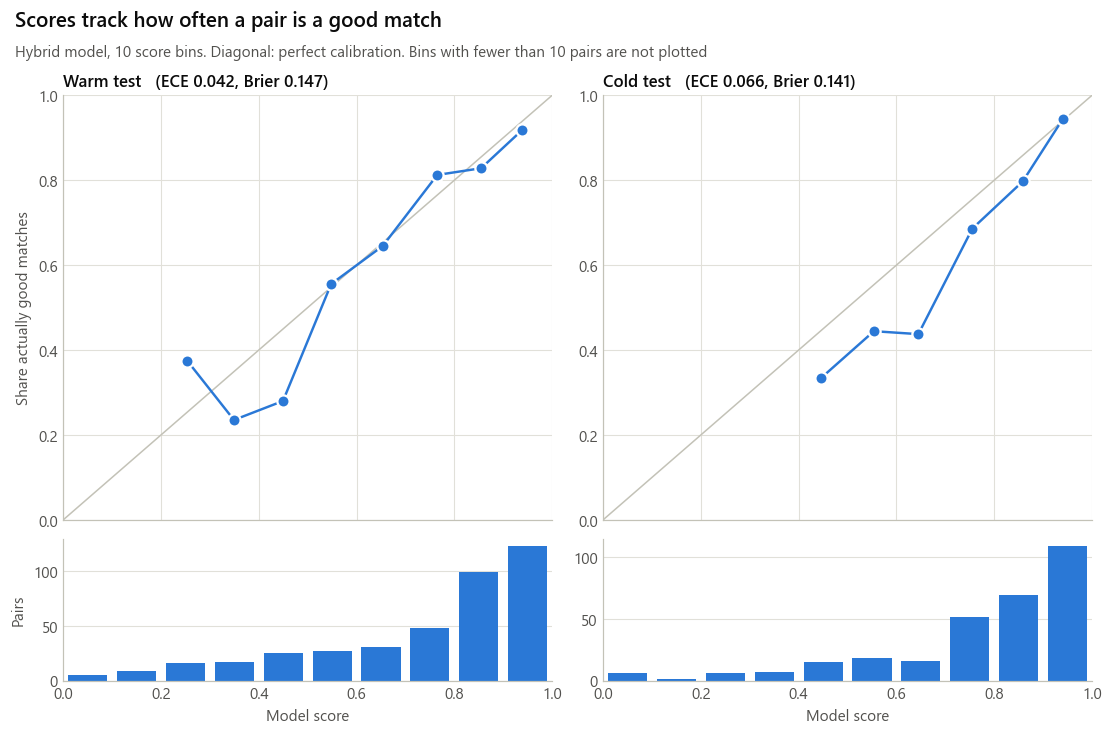

,ECE,Brier,Brier if always predicting the base rate
Warm test,0.042,0.147,0.203
Cold test,0.066,0.141,0.204


In [15]:
def expected_calibration_error(labels, scores, bins=10):
    edges = np.linspace(0, 1, bins + 1)
    index = np.clip(np.digitize(scores, edges) - 1, 0, bins - 1)
    return sum(abs(labels[index == bin_].mean() - scores[index == bin_].mean()) * (index == bin_).mean() for bin_ in range(bins) if (index == bin_).any())


figure, axes = plt.subplots(2, 2, figsize=(10, 6), layout="constrained", sharex=True, gridspec_kw={"height_ratios": [3, 1]})
rows = {}
for column, split in enumerate(TEST_SPLITS):
    part = parts[split]
    labels, scores = part.label.to_numpy(), part.hybrid.to_numpy()
    edges = np.linspace(0, 1, 11)
    index = np.clip(np.digitize(scores, edges) - 1, 0, 9)
    table = pd.DataFrame({"bin": index, "score": scores, "label": labels}).groupby("bin").agg(mean_score=("score", "mean"), actual_rate=("label", "mean"), pairs=("label", "size"))
    reliable = table[table.pairs >= 10]
    top = axes[0, column]
    top.plot([0, 1], [0, 1], color=AXIS, linewidth=1)
    top.plot(reliable.mean_score, reliable.actual_rate, color=BLUE, marker="o", markersize=8, markeredgecolor=SURFACE, markeredgewidth=1.5)
    ece = expected_calibration_error(labels, scores)
    brier = points[split]["hybrid"]["brier"]
    top.set_title(f"{SPLIT_NAMES[split]}   (ECE {ece:.3f}, Brier {brier:.3f})")
    top.set_xlim(0, 1)
    top.set_ylim(0, 1)
    top.grid(True)
    top.set_axisbelow(True)
    bottom = axes[1, column]
    bottom.bar((edges[:-1] + edges[1:])[table.index] / 2, table.pairs, width=0.08, color=BLUE)
    bottom.set_xlabel("Model score")
    bottom.grid(True, axis="y")
    bottom.set_axisbelow(True)
    rows[SPLIT_NAMES[split]] = {"ECE": ece, "Brier": brier, "Brier if always predicting the base rate": labels.mean() * (1 - labels.mean())}
    display(table.round(3).rename_axis(f"{SPLIT_NAMES[split]} bin"))
axes[0, 0].set_ylabel("Share actually good matches")
axes[1, 0].set_ylabel("Pairs")
headed(figure, "Scores track how often a pair is a good match", "Hybrid model, 10 score bins. Diagonal: perfect calibration. Bins with fewer than 10 pairs are not plotted")
show(figure, "13_calibration")
display(pd.DataFrame(rows).T.round(3))

### Figure 14. Score distribution by actual label

Good matches pile up above 0.8, while non-matches spread across the whole range, including many above 0.7. No single threshold can separate them cleanly. A sizeable group of non-matches score as high as real matches, which fits the labels' deliberate random component and hidden traits the model cannot see.

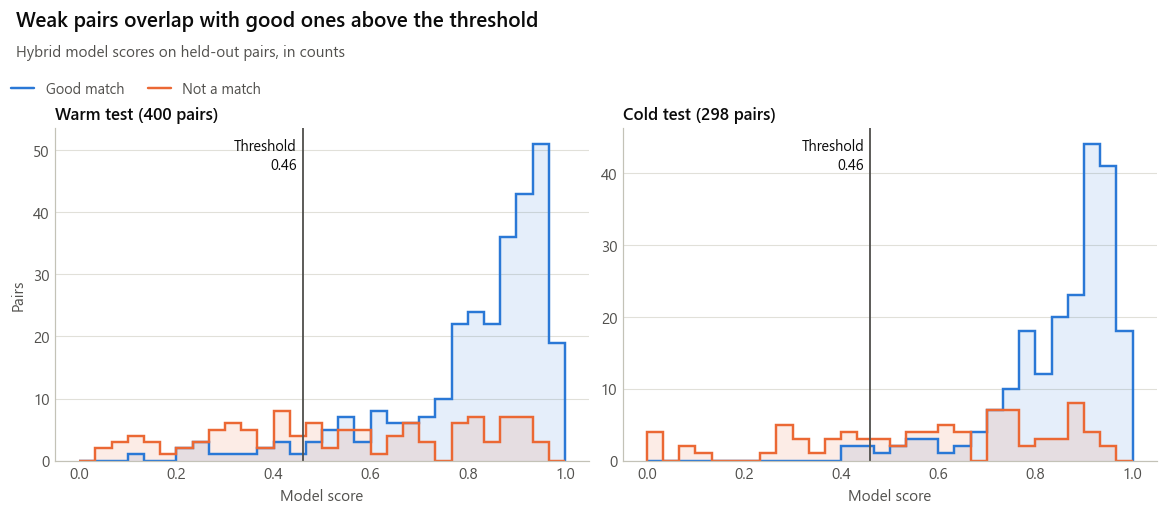

count   mean    std    min    25%    50%    75%    max
split     actual                                                             
Cold test Good match   213.0  0.855  0.120  0.419  0.799  0.900  0.938  0.988
          Not a match   85.0  0.584  0.253  0.007  0.404  0.615  0.767  0.945
Warm test Good match   287.0  0.814  0.167  0.128  0.771  0.872  0.932  0.988
          Not a match  113.0  0.541  0.262  0.052  0.332  0.534  0.795  0.965

In [16]:
figure, axes = plt.subplots(1, 2, figsize=(10.5, 3.7), layout="constrained", sharex=True)
edges = np.linspace(0, 1, 31)
for axis, split in zip(axes, TEST_SPLITS):
    part = parts[split]
    for label, colour, name in ((1, GOOD_COLOUR, "Good match"), (0, NOT_COLOUR, "Not a match")):
        values = part.loc[part.label == label, "hybrid"]
        axis.hist(values, bins=edges, histtype="stepfilled", color=colour, alpha=0.12)
        axis.hist(values, bins=edges, histtype="step", color=colour, linewidth=1.6, label=name)
    axis.axvline(THRESHOLD, color=INK_2, linewidth=1.2)
    axis.text(THRESHOLD - 0.012, axis.get_ylim()[1] * 0.97, f"Threshold\n{THRESHOLD:.2f}", ha="right", va="top", color=INK, fontsize=9.5)
    axis.set_title(f"{SPLIT_NAMES[split]} ({len(part)} pairs)")
    axis.set_xlabel("Model score")
    axis.grid(True, axis="y")
    axis.set_axisbelow(True)
axes[0].set_ylabel("Pairs")
handles = [Line2D([], [], color=GOOD_COLOUR, label="Good match"), Line2D([], [], color=NOT_COLOUR, label="Not a match")]
top_legend(figure, handles, [item.get_label() for item in handles], 2)
headed(figure, "Weak pairs overlap with good ones above the threshold", "Hybrid model scores on held-out pairs, in counts")
show(figure, "14_score_distribution")
display(pairs[pairs.split.isin(TEST_SPLITS)].assign(split=lambda frame: frame.split.map(SPLIT_NAMES), actual=lambda frame: frame.label.map({0: "Not a match", 1: "Good match"})).groupby(["split", "actual"]).hybrid.describe().round(3))

### Figure 15. What changes as the threshold moves (validation data)

F1 is almost flat from 0.05 to 0.65, so choosing the threshold by F1 has little effect on F1 and a large effect on specificity. Validation figures from the table below:

| Threshold | Precision | Recall | Specificity |
|---|---|---|---|
| 0.46 (current) | 0.82 | 0.95 | 0.38 |
| 0.60 | 0.85 | 0.90 | 0.53 |
| 0.75 | 0.89 | 0.78 | 0.70 |

This shows the trade-off only. Nothing was changed: the live threshold stays 0.46, and any change is your decision and needs its own review. Because the app ranks candidates and leaves the final decision to a recruiter, a missed good match may be the costlier error, which is a reasonable defence of the current setting.

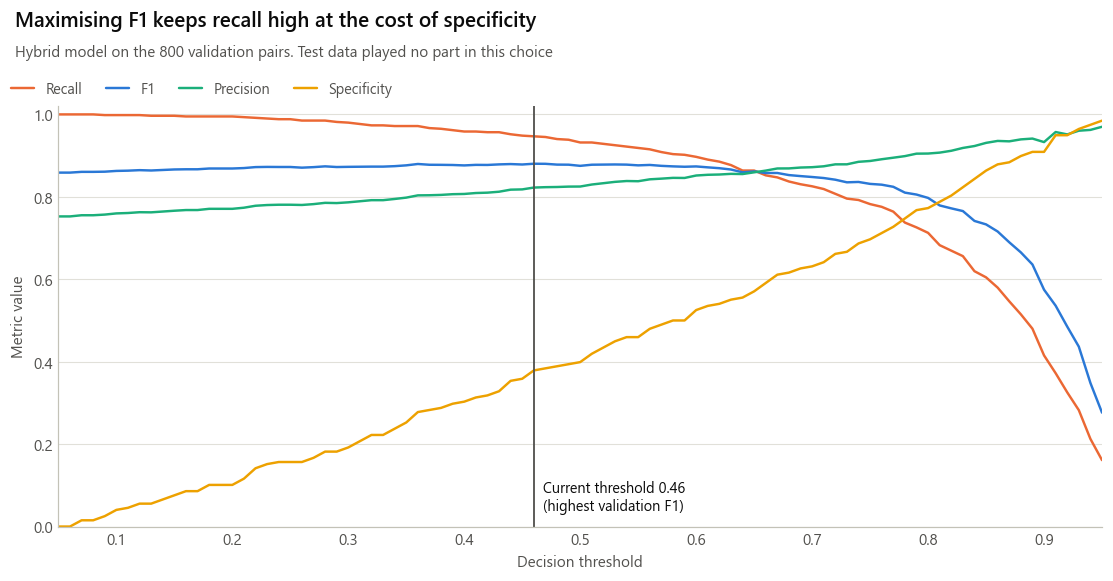

,accuracy,precision,recall,specificity,f1,balanced_accuracy,tp,fp,fn,tn
threshold,,,,,,,,,,
0.46,0.806,0.823,0.947,0.379,0.880,0.663,570,123,32,75
0.50,0.800,0.825,0.932,0.399,0.875,0.665,561,119,41,79
0.60,0.805,0.852,0.897,0.525,0.874,0.711,540,94,62,104
0.70,0.778,0.872,0.826,0.631,0.848,0.728,497,73,105,125
0.75,0.761,0.887,0.782,0.697,0.831,0.740,471,60,131,138
0.80,0.728,0.905,0.713,0.773,0.797,0.743,429,45,173,153
0.85,0.669,0.931,0.605,0.864,0.733,0.734,364,27,238,171
0.90,0.538,0.933,0.415,0.909,0.575,0.662,250,18,352,180


In [17]:
validation = pairs[pairs.split == "validation"]
grid = np.round(np.linspace(0.05, 0.95, 91), 2)
sweep = pd.DataFrame([{"threshold": value, **at_threshold(validation.label, validation.hybrid, value)} for value in grid]).set_index("threshold")
assert abs(sweep.f1.idxmax() - round(THRESHOLD, 2)) < 1e-9

figure, axis = plt.subplots(figsize=(10, 4.3), layout="constrained")
lines = {"recall": ("Recall", ORANGE), "f1": ("F1", BLUE), "precision": ("Precision", AQUA), "specificity": ("Specificity", YELLOW)}
for metric, (label, colour) in lines.items():
    axis.plot(sweep.index, sweep[metric], color=colour, label=label)
axis.axvline(THRESHOLD, color=INK_2, linewidth=1.2)
axis.text(THRESHOLD + 0.008, 0.03, f"Current threshold {THRESHOLD:.2f}\n(highest validation F1)", color=INK, fontsize=9.5, va="bottom")
axis.set_xlim(0.05, 0.95)
axis.set_ylim(0, 1.02)
axis.set_xlabel("Decision threshold")
axis.set_ylabel("Metric value")
axis.grid(True, axis="y")
top_legend(figure, columns=4)
headed(figure, "Maximising F1 keeps recall high at the cost of specificity", f"Hybrid model on the {len(validation)} validation pairs. Test data played no part in this choice")
show(figure, "15_threshold_tradeoff")
display(sweep.loc[[round(THRESHOLD, 2), 0.5, 0.6, 0.7, 0.75, 0.8, 0.85, 0.9], ["accuracy", "precision", "recall", "specificity", "f1", "balanced_accuracy", "tp", "fp", "fn", "tn"]].round(3))

### Figure 16. Ranking quality

Ranking is the job the product actually does. When ranking candidates for a job, the top candidate is a good match 93% of the time, against 71% for a random order. When ranking jobs for a candidate, it is 94% against 72%. The hybrid model and fixed weights are effectively tied, and both beat semantic-only.

Within-group results are limited by the data: candidates have at most five jobs, so NDCG@5 starts high (0.81 to 0.89 at random) and Precision@3 covers much of each candidate's list. Hard eligibility rules run before this scoring in the live app and are not part of these numbers.

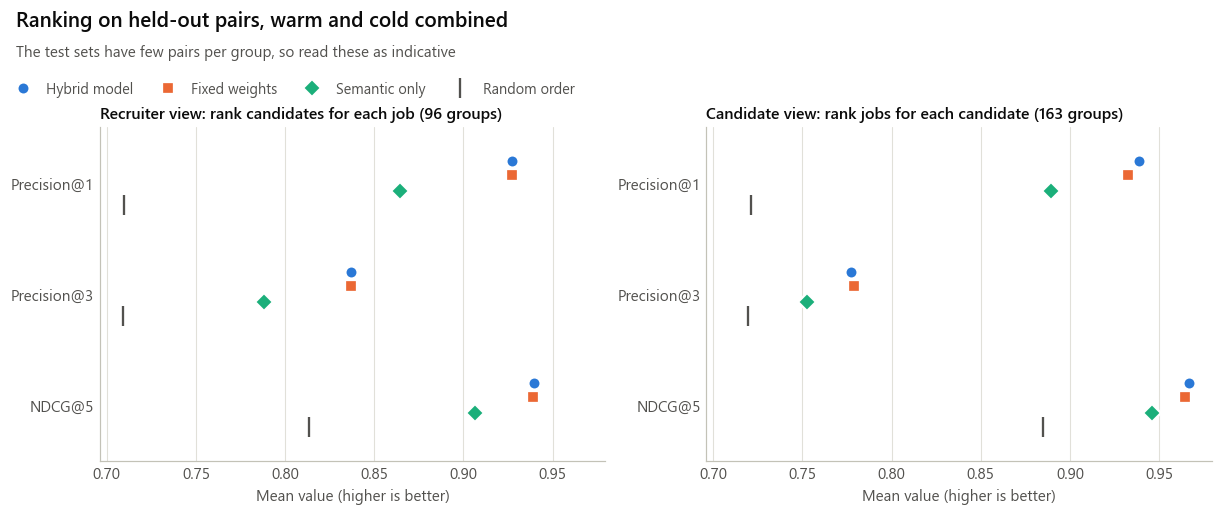

Recruiter view: rank candidates for each job


,Hybrid model,Fixed weights,Semantic only,Random order
Precision@1,0.927,0.927,0.865,0.710
Precision@3,0.837,0.837,0.788,0.709
NDCG@5,0.940,0.939,0.907,0.814


Candidate view: rank jobs for each candidate


,Hybrid model,Fixed weights,Semantic only,Random order
Precision@1,0.939,0.933,0.890,0.721
Precision@3,0.777,0.779,0.753,0.719
NDCG@5,0.967,0.965,0.946,0.885


In [18]:
def ranking_metrics(frame, group, score, shuffle_seed=None):
    """Mean Precision@1, Precision@3 and NDCG@5 over groups with at least two pairs."""
    rng = np.random.default_rng(shuffle_seed) if shuffle_seed is not None else None
    results = []
    for _, part in frame.groupby(group):
        if len(part) < 2:
            continue
        if rng is None:
            ordered = part.sort_values(score, ascending=False).label.to_numpy()
        else:
            ordered = rng.permutation(part.label.to_numpy())
        ideal = np.sort(part.label.to_numpy())[::-1][:5]
        discounts = 1 / np.log2(np.arange(2, 7))
        best = (ideal * discounts[:len(ideal)]).sum()
        results.append({
            "Precision@1": ordered[0], "Precision@3": ordered[:3].mean(),
            "NDCG@5": (ordered[:5] * discounts[:len(ordered[:5])]).sum() / best if best else np.nan,
        })
    return pd.DataFrame(results).mean(), len(results)


tested = pairs[pairs.split.isin(TEST_SPLITS)]
views = {"job_id": "Recruiter view: rank candidates for each job", "candidate_id": "Candidate view: rank jobs for each candidate"}
ranking = {}
for group in views:
    results = {MODELS[name][0]: ranking_metrics(tested, group, name)[0] for name in MODELS}
    results["Random order"] = pd.concat([ranking_metrics(tested, group, "hybrid", seed)[0] for seed in range(200)], axis=1).mean(axis=1)
    ranking[group] = pd.DataFrame(results)

figure, axes = plt.subplots(1, 2, figsize=(11, 3.7), layout="constrained", sharex=True)
styles = {**{MODELS[name][0]: (MODELS[name][1], MODELS[name][2]) for name in MODELS}, "Random order": (INK_2, "|")}
for axis, (group, title) in zip(axes, views.items()):
    table = ranking[group]
    count = ranking_metrics(tested, group, "hybrid")[1]
    positions = np.arange(len(table.index))[::-1]
    for offset, (name, (colour, marker)) in zip((0.2, 0.07, -0.07, -0.2), styles.items()):
        axis.plot(table[name], positions + offset, marker, color=colour, markersize=8 if marker != "|" else 13, markeredgecolor=SURFACE if marker != "|" else INK_2, markeredgewidth=1.5, linestyle="none", label=name)
    axis.set_yticks(positions, table.index)
    axis.set_ylim(-0.5, len(table.index) - 0.5)
    axis.set_title(f"{title} ({count} groups)", fontsize=10.5)
    axis.set_xlabel("Mean value (higher is better)")
    axis.grid(True, axis="x")
    axis.set_axisbelow(True)
top_legend(figure, columns=4)
headed(figure, "Ranking on held-out pairs, warm and cold combined", "The test sets have few pairs per group, so read these as indicative")
show(figure, "16_ranking_quality")
for group, title in views.items():
    print(title)
    display(ranking[group].round(3))

### Figure 17. Results by role

Software Engineer ranks best (ROC-AUC 0.90) and DevOps Engineer lowest (0.77). Specificity differs far more: 58% against 22%, so weak DevOps pairs are much more likely to be let through. Most intervals overlap, with 28 to 48 non-matches per role, so these are leads to check, not firm differences. This is a comparison across job roles, not a fairness audit of people.

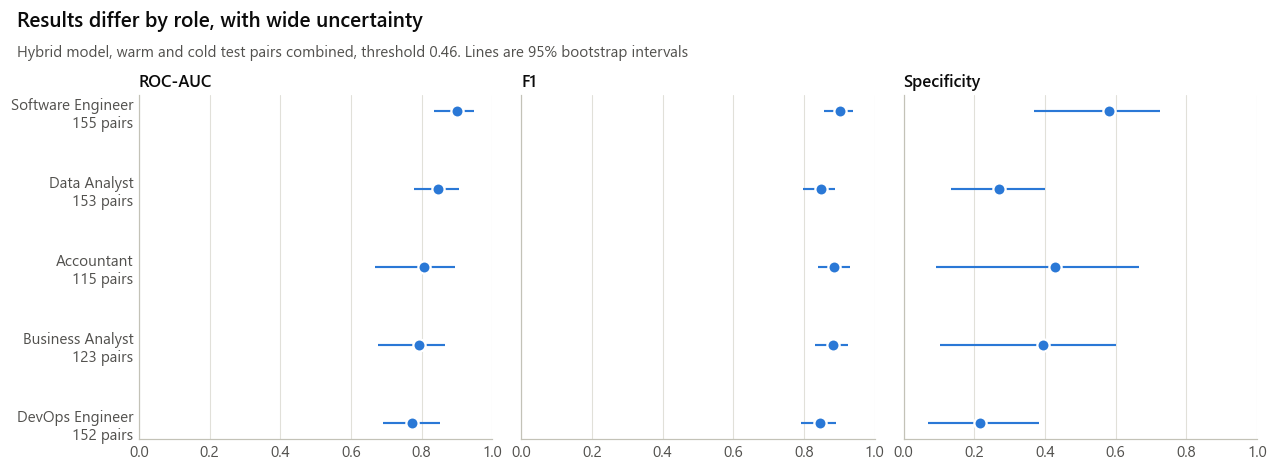

,pairs,not_a_match,good_match_rate,roc_auc,roc_auc_low,roc_auc_high,f1,specificity
role,,,,,,,,
Software Engineer,155,43,0.723,0.900,0.834,0.949,0.903,0.581
Data Analyst,153,48,0.686,0.846,0.778,0.905,0.848,0.271
Accountant,115,28,0.757,0.806,0.667,0.894,0.886,0.429
Business Analyst,123,33,0.732,0.792,0.677,0.866,0.883,0.394
DevOps Engineer,152,46,0.697,0.773,0.691,0.851,0.846,0.217


In [19]:
rows = []
for role, part in tested.groupby("role"):
    labels, scores = part.label.to_numpy(), part.hybrid.to_numpy()
    groups = list(part.reset_index(drop=True).groupby("candidate_id").indices.values())
    samples = {"roc_auc": [], "f1": [], "specificity": []}
    for _ in range(1000):
        chosen = np.concatenate([groups[index] for index in RANDOM.integers(len(groups), size=len(groups))])
        result = at_threshold(labels[chosen], scores[chosen], THRESHOLD)
        samples["roc_auc"].append(auc(labels[chosen], scores[chosen]))
        samples["f1"].append(result["f1"])
        samples["specificity"].append(result["specificity"])
    point = at_threshold(labels, scores, THRESHOLD)
    row = {"role": role, "pairs": len(part), "not_a_match": int((labels == 0).sum()), "good_match_rate": labels.mean(), "roc_auc": auc(labels, scores), "f1": point["f1"], "specificity": point["specificity"]}
    for metric, values in samples.items():
        row[f"{metric}_low"], row[f"{metric}_high"] = np.nanpercentile(values, [2.5, 97.5])
    rows.append(row)
by_role = pd.DataFrame(rows).sort_values("roc_auc", ascending=False).set_index("role")

figure, axes = plt.subplots(1, 3, figsize=(11.5, 3.6), layout="constrained", sharey=True)
positions = np.arange(len(by_role))[::-1]
for axis, (metric, title) in zip(axes, {"roc_auc": "ROC-AUC", "f1": "F1", "specificity": "Specificity"}.items()):
    axis.hlines(positions, by_role[f"{metric}_low"], by_role[f"{metric}_high"], color=BLUE, linewidth=1.4)
    axis.plot(by_role[metric], positions, "o", color=BLUE, markersize=8, markeredgecolor=SURFACE, markeredgewidth=1.5)
    axis.set_title(title)
    axis.set_xlim(0, 1)
    axis.grid(True, axis="x")
    axis.set_axisbelow(True)
axes[0].set_yticks(positions, [f"{role}\n{int(row.pairs)} pairs" for role, row in by_role.iterrows()])
headed(figure, "Results differ by role, with wide uncertainty", f"Hybrid model, warm and cold test pairs combined, threshold {THRESHOLD:.2f}. Lines are 95% bootstrap intervals")
show(figure, "17_results_by_role")
display(by_role[["pairs", "not_a_match", "good_match_rate", "roc_auc", "roc_auc_low", "roc_auc_high", "f1", "specificity"]].round(3))

### Figure 18. Old model against new, and a fresh population

The current model reaches ROC-AUC 0.81 to 0.86 against 0.67 to 0.74 for the previous one, and these match the figures in `docs/ROADMAP.txt`. Two cautions before quoting that gap:

- **Part of it comes from the labels.** The previous model was trained on older labels and is tested here on the v3 labels. The roadmap's retrained v1 reached 0.706/0.746 on the training seed and 0.749/0.752 on the fresh seed, so that is the fairer comparison. On the older v2 labels, the two models tie on warm data (0.799 each) and v2 leads on cold (0.870 against 0.825).
- **The improvement depends on an assumption.** The v3 labels assume candidates often describe a skill they hold under another name. That is what related-skill overlap was designed to catch, so the gain is conditional on that assumption holding in reality.

The fresh population comes from the same generator with a different seed. It checks that the model did not fit one random draw. It does not provide outside evidence.

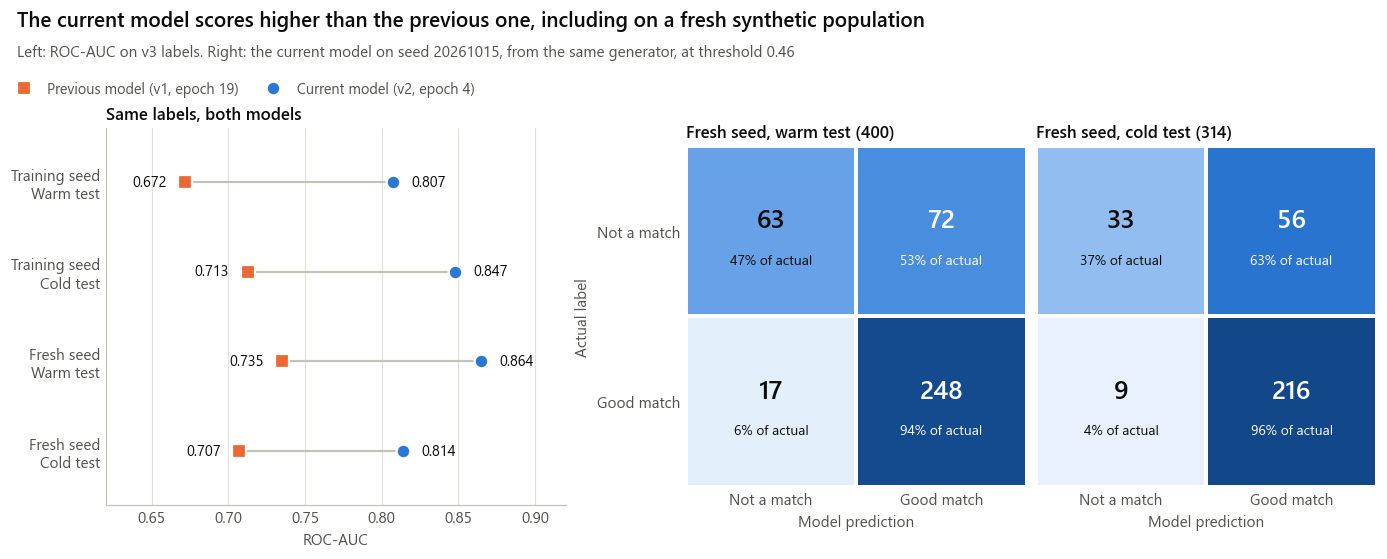

,population,split,model,pairs,roc_auc,threshold,accuracy,precision,recall,specificity,f1,balanced_accuracy,log_loss
0,Training seed,Warm test,"Previous model (v1, epoch 19)",400,0.672,0.44,0.620,0.792,0.638,0.575,0.707,0.606,0.753
1,Training seed,Cold test,"Previous model (v1, epoch 19)",298,0.713,0.44,0.651,0.785,0.704,0.518,0.743,0.611,0.646
2,Training seed,Warm test,"Current model (v2, epoch 4)",400,0.807,0.46,0.800,0.805,0.951,0.416,0.872,0.684,0.459
3,Training seed,Cold test,"Current model (v2, epoch 4)",298,0.847,0.46,0.792,0.781,0.986,0.306,0.871,0.646,0.435
4,Fresh seed,Warm test,"Previous model (v1, epoch 19)",400,0.735,0.44,0.662,0.810,0.642,0.704,0.716,0.673,0.672
5,Fresh seed,Cold test,"Previous model (v1, epoch 19)",314,0.707,0.44,0.672,0.811,0.707,0.584,0.755,0.645,0.669
6,Fresh seed,Warm test,"Current model (v2, epoch 4)",400,0.864,0.46,0.778,0.775,0.936,0.467,0.848,0.701,0.440
7,Fresh seed,Cold test,"Current model (v2, epoch 4)",314,0.814,0.46,0.793,0.794,0.960,0.371,0.869,0.665,0.465


In [20]:
def scored(seed, contract, model):
    frame, _, _ = load_pairs(seed, contract)
    frame["hybrid"] = sigmoid_score(model, frame[list(FEATURES)].to_numpy())
    return frame


populations = {"Training seed": TRAINING_SEED, "Fresh seed": FRESH_SEED}
versions = {"Previous model (v1, epoch 19)": (CONTRACT_V1, model_v1, ORANGE, "s"), "Current model (v2, epoch 4)": (CONTRACT_V2, model_v2, BLUE, "o")}
frames = {(population, version): scored(seed, contract, model) for population, seed in populations.items() for version, (contract, model, _, _) in versions.items()}

rows = []
for (population, version), frame in frames.items():
    for split in TEST_SPLITS:
        part = frame[frame.split == split]
        threshold = versions[version][1]["decision_threshold"]
        rows.append({"population": population, "split": SPLIT_NAMES[split], "model": version, "pairs": len(part), "roc_auc": auc(part.label.to_numpy(), part.hybrid.to_numpy()), "threshold": threshold, **at_threshold(part.label, part.hybrid, threshold), "log_loss": log_loss(part.label, part.hybrid)})
generations = pd.DataFrame(rows)

figure = plt.figure(figsize=(12.5, 4.1), layout="constrained")
grid = figure.add_gridspec(1, 3, width_ratios=[1.35, 1, 1])
axis = figure.add_subplot(grid[0])
labels = []
for position, ((population, split), group) in zip(range(3, -1, -1), generations.groupby(["population", "split"], sort=False)):
    values = group.set_index("model").roc_auc
    axis.plot(values.values, [position, position], color=AXIS, linewidth=1.4, zorder=1)
    for version, (_, _, colour, marker) in versions.items():
        axis.plot(values[version], position, marker, color=colour, markersize=9, markeredgecolor=SURFACE, markeredgewidth=1.5, zorder=3, label=version)
        side = 1 if values[version] == values.max() else -1
        axis.text(values[version] + side * 0.012, position, f"{values[version]:.3f}", ha="left" if side > 0 else "right", va="center", color=INK, fontsize=9.5)
    labels.append(f"{population}\n{split}")
axis.set_yticks(range(3, -1, -1), labels)
axis.set_ylim(-0.6, 3.6)
axis.set_xlim(0.62, 0.92)
axis.set_xlabel("ROC-AUC")
axis.set_title("Same labels, both models")
axis.grid(True, axis="x")
axis.set_axisbelow(True)
handles, names = axis.get_legend_handles_labels()
unique = dict(zip(names, handles))
top_legend(figure, list(unique.values()), list(unique), 2)
fresh = frames[("Fresh seed", "Current model (v2, epoch 4)")]
for index, split in enumerate(TEST_SPLITS):
    part = fresh[fresh.split == split]
    confusion_panel(figure.add_subplot(grid[index + 1]), part.label, part.hybrid, THRESHOLD, f"Fresh seed, {SPLIT_NAMES[split].lower()} ({len(part)})", index == 0)
headed(figure, "The current model scores higher than the previous one, including on a fresh synthetic population", f"Left: ROC-AUC on v3 labels. Right: the current model on seed {FRESH_SEED}, from the same generator, at threshold {THRESHOLD:.2f}")
show(figure, "18_model_generations_and_fresh_population")
display(generations.drop(columns=["tp", "fp", "fn", "tn"]).round(3))

---
# Part 4. Other algorithms

The served model is a linear model. This part tests whether a non-linear algorithm does better on the same three inputs. It is a report-only experiment: **nothing here changes the live model.**

- **Same inputs and splits** as the served model, seed 42.
- **Tuning on validation data only**, by the same rule as the served model (lowest validation log loss), with each threshold then set by validation F1. Random forest tried 16 settings and gradient boosting 36.
- **Test data used once**, after tuning, including the fresh population from seed 20261015.

### Tuning random forest and gradient boosting on validation data

In [21]:
from itertools import product
from time import perf_counter

from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier

X = pairs[list(FEATURES)].to_numpy()
y = pairs.label.to_numpy()
in_train, in_validation = (pairs.split == "train").to_numpy(), (pairs.split == "validation").to_numpy()
F1_GRID = np.linspace(0.05, 0.95, 91)
SEARCHES = {
    "random_forest": (RandomForestClassifier, {"n_estimators": [300], "max_depth": [3, 5, 8, None], "min_samples_leaf": [1, 5, 20, 50]}),
    "gradient_boosting": (GradientBoostingClassifier, {"n_estimators": [50, 100, 200, 400], "learning_rate": [0.02, 0.05, 0.1], "max_depth": [1, 2, 3]}),
}
fitted, searches = {}, {}
for name, (factory, grid) in SEARCHES.items():
    rows = []
    for values in product(*grid.values()):
        settings = dict(zip(grid, values))
        started = perf_counter()
        model = factory(random_state=TRAINING_SEED, **settings).fit(X[in_train], y[in_train])
        rows.append({**settings, "validation_log_loss": log_loss(y[in_validation], model.predict_proba(X[in_validation])[:, 1]), "seconds": perf_counter() - started, "model": model})
    searches[name] = pd.DataFrame(rows)
    # The same selection rule as the served model: lowest validation log loss.
    fitted[name] = searches[name].loc[searches[name].validation_log_loss.idxmin()]
    print(name, {key: fitted[name][key] for key in grid}, f"validation log loss {fitted[name].validation_log_loss:.4f}, {len(rows)} settings tried")

ALGORITHMS = {"hybrid": ("Logistic regression (served)", BLUE, "o"), "random_forest": ("Random forest", ORANGE, "^"), "gradient_boosting": ("Gradient boosting", AQUA, "D")}
for name in SEARCHES:
    pairs[name] = fitted[name].model.predict_proba(X)[:, 1]
fresh_pairs = frames[("Fresh seed", "Current model (v2, epoch 4)")].copy()
for name in SEARCHES:
    fresh_pairs[name] = fitted[name].model.predict_proba(fresh_pairs[list(FEATURES)].to_numpy())[:, 1]
ALGORITHM_THRESHOLDS = {name: float(max(F1_GRID, key=lambda value: at_threshold(y[in_validation], pairs[name].to_numpy()[in_validation], value)["f1"])) for name in ALGORITHMS}
assert abs(ALGORITHM_THRESHOLDS["hybrid"] - THRESHOLD) < 1e-9
print("Validation-tuned thresholds:", {name: round(value, 2) for name, value in ALGORITHM_THRESHOLDS.items()})
display(pd.concat({name: frame.drop(columns="model").sort_values("validation_log_loss").head(3) for name, frame in searches.items()}).round(4))

random_forest {'n_estimators': np.int64(300), 'max_depth': np.float64(nan), 'min_samples_leaf': np.int64(20)} validation log loss 0.4258, 16 settings tried


gradient_boosting {'n_estimators': np.int64(200), 'learning_rate': np.float64(0.05), 'max_depth': np.int64(1)} validation log loss 0.4253, 36 settings tried


Validation-tuned thresholds: {'hybrid': 0.46, 'random_forest': 0.49, 'gradient_boosting': 0.48}


n_estimators  max_depth  min_samples_leaf  \
random_forest     14           300        NaN              20.0   
                  10           300        8.0              20.0   
                  6            300        5.0              20.0   
gradient_boosting 21           200        1.0               NaN   
                  15           100        1.0               NaN   
                  24           200        1.0               NaN   

                      validation_log_loss  seconds  learning_rate  
random_forest     14               0.4258   1.7639            NaN  
                  10               0.4262   1.8357            NaN  
                  6                0.4281   1.9586            NaN  
gradient_boosting 21               0.4253   0.5977           0.05  
                  15               0.4254   0.2807           0.10  
                  24               0.4262   1.3362           0.10

### Figure 19. Logistic regression against random forest and gradient boosting

**Both tree models point the same way in all four tests.** Against logistic regression, gradient boosting gains 0.011 to 0.032 ROC-AUC and random forest 0.001 to 0.028, and both have lower log loss. The gain is small. On the training seed every ROC-AUC interval includes zero, and only gradient boosting on the fresh population clearly excludes it (+0.018 warm, +0.032 cold; its warm interval only just clears zero).

**F1 does not change:** every interval includes zero, with differences between -0.010 and +0.003.

**Random forest rejects more weak pairs** (specificity 9 to 13 points higher, all intervals exclude zero), but it pays with lower recall (about 3 to 5 points), so that is a trade-off and not a clean win.

**How far to take this.** These 32 comparisons were not corrected for testing many things at once, and the four tests share the same trained models, so they are not four independent confirmations. Gradient boosting's best setting used trees of depth 1, which cannot combine inputs, so the gain likely comes from curved effects of single inputs. Because the labels come from a generator, that curve may be a property of the generator and not of real hiring.

**What this means for the report.** Do not claim logistic regression was the most accurate. Its case rests on being explainable and small, for a small accuracy cost on synthetic data. No model was switched: changing it would need real evidence from the gold slice and your approval.

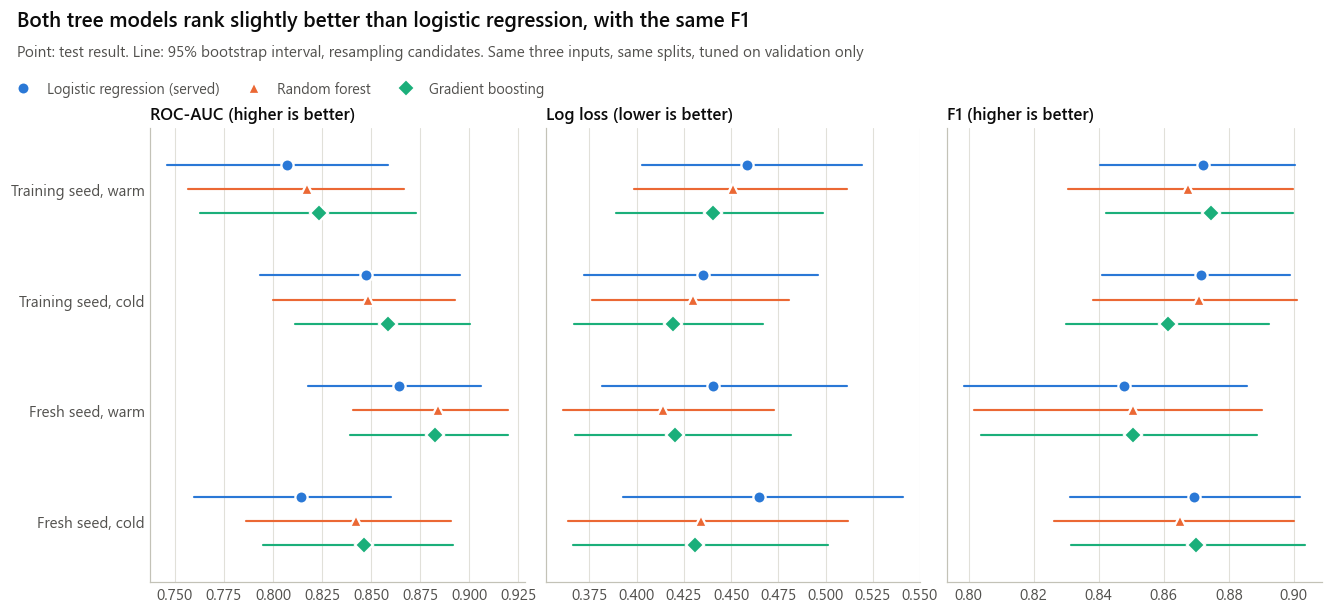

,evaluation,model,threshold,roc_auc,roc_auc_low,roc_auc_high,log_loss,brier,f1,accuracy,precision,recall,specificity
0,"Training seed, warm",Logistic regression (served),0.46,0.807,0.746,0.858,0.459,0.147,0.872,0.800,0.805,0.951,0.416
1,"Training seed, warm",Random forest,0.49,0.817,0.756,0.867,0.451,0.142,0.868,0.800,0.826,0.913,0.513
2,"Training seed, warm",Gradient boosting,0.48,0.824,0.763,0.873,0.440,0.138,0.875,0.805,0.812,0.948,0.442
3,"Training seed, cold",Logistic regression (served),0.46,0.847,0.793,0.895,0.435,0.141,0.871,0.792,0.781,0.986,0.306
4,"Training seed, cold",Random forest,0.49,0.848,0.800,0.893,0.430,0.139,0.871,0.799,0.805,0.948,0.424
5,"Training seed, cold",Gradient boosting,0.48,0.859,0.811,0.901,0.419,0.137,0.861,0.779,0.779,0.962,0.318
6,"Fresh seed, warm",Logistic regression (served),0.46,0.864,0.818,0.906,0.440,0.144,0.848,0.778,0.775,0.936,0.467
7,"Fresh seed, warm",Random forest,0.49,0.884,0.841,0.920,0.414,0.134,0.850,0.792,0.814,0.891,0.600
8,"Fresh seed, warm",Gradient boosting,0.48,0.883,0.839,0.920,0.420,0.136,0.851,0.788,0.796,0.913,0.541
9,"Fresh seed, cold",Logistic regression (served),0.46,0.814,0.760,0.860,0.465,0.152,0.869,0.793,0.794,0.960,0.371


,evaluation,model minus logistic regression,metric,difference,low,high,interval excludes 0
0,"Training seed, warm",Random forest,roc_auc,0.010,-0.010,0.032,False
1,"Training seed, warm",Random forest,log_loss,-0.007,-0.031,0.016,False
2,"Training seed, warm",Random forest,f1,-0.005,-0.027,0.016,False
3,"Training seed, warm",Random forest,specificity,0.097,0.017,0.188,True
4,"Training seed, warm",Gradient boosting,roc_auc,0.016,-0.002,0.036,False
5,"Training seed, warm",Gradient boosting,log_loss,-0.018,-0.037,0.000,False
6,"Training seed, warm",Gradient boosting,f1,0.002,-0.013,0.016,False
7,"Training seed, warm",Gradient boosting,specificity,0.027,-0.040,0.083,False
8,"Training seed, cold",Random forest,roc_auc,0.001,-0.020,0.024,False
9,"Training seed, cold",Random forest,log_loss,-0.005,-0.030,0.019,False


In [22]:
def loss_of(labels, scores):
    clipped = np.clip(scores, 1e-15, 1 - 1e-15)
    return float(-(labels * np.log(clipped) + (1 - labels) * np.log(1 - clipped)).mean())


def algorithm_results(part, resamples=1000):
    labels = part.label.to_numpy()
    scores = {name: part[name].to_numpy() for name in ALGORITHMS}

    def measure(chosen):
        output = {}
        for name in ALGORITHMS:
            result = at_threshold(labels[chosen], scores[name][chosen], ALGORITHM_THRESHOLDS[name])
            output[name] = {
                "roc_auc": auc(labels[chosen], scores[name][chosen]), "log_loss": loss_of(labels[chosen], scores[name][chosen]), "brier": float(((scores[name][chosen] - labels[chosen]) ** 2).mean()),
                "f1": result["f1"], "accuracy": result["accuracy"], "specificity": result["specificity"], "recall": result["recall"], "precision": result["precision"],
            }
        return output

    groups = list(part.reset_index(drop=True).groupby("candidate_id").indices.values())
    samples = [measure(np.concatenate([groups[index] for index in RANDOM.integers(len(groups), size=len(groups))])) for _ in range(resamples)]
    return measure(np.arange(len(labels))), samples


EVALUATIONS = {
    "Training seed, warm": pairs[pairs.split == "warm_test"], "Training seed, cold": pairs[pairs.split == "cold_test"],
    "Fresh seed, warm": fresh_pairs[fresh_pairs.split == "warm_test"], "Fresh seed, cold": fresh_pairs[fresh_pairs.split == "cold_test"],
}
algorithm_points, algorithm_samples = {}, {}
for label, part in EVALUATIONS.items():
    algorithm_points[label], algorithm_samples[label] = algorithm_results(part)

records, gaps = [], []
for label in EVALUATIONS:
    for name, (title, _, _) in ALGORITHMS.items():
        record = {"evaluation": label, "model": title, "threshold": round(ALGORITHM_THRESHOLDS[name], 2), **algorithm_points[label][name]}
        low, high = np.percentile([sample[name]["roc_auc"] for sample in algorithm_samples[label]], [2.5, 97.5])
        records.append({**record, "roc_auc_low": low, "roc_auc_high": high})
        if name != "hybrid":
            for metric in ("roc_auc", "log_loss", "f1", "specificity"):
                gap = np.array([sample[name][metric] - sample["hybrid"][metric] for sample in algorithm_samples[label]])
                low, high = np.percentile(gap, [2.5, 97.5])
                gaps.append({"evaluation": label, "model minus logistic regression": title, "metric": metric, "difference": algorithm_points[label][name][metric] - algorithm_points[label]["hybrid"][metric], "low": low, "high": high, "interval excludes 0": bool(low > 0 or high < 0)})
algorithm_table = pd.DataFrame(records)
algorithm_gaps = pd.DataFrame(gaps)
algorithm_table.to_csv(FIGURES / "algorithm_comparison.csv", index=False)

panels = {"roc_auc": "ROC-AUC (higher is better)", "log_loss": "Log loss (lower is better)", "f1": "F1 (higher is better)"}
figure, axes = plt.subplots(1, 3, figsize=(12, 4.6), layout="constrained", sharey=True)
offsets = {"hybrid": 0.22, "random_forest": 0, "gradient_boosting": -0.22}
rows = list(EVALUATIONS)
for axis, (metric, title) in zip(axes, panels.items()):
    for row, label in enumerate(rows):
        base = len(rows) - 1 - row
        for name, (series, colour, marker) in ALGORITHMS.items():
            low, high = np.percentile([sample[name][metric] for sample in algorithm_samples[label]], [2.5, 97.5])
            axis.plot([low, high], [base + offsets[name]] * 2, color=colour, linewidth=1.4, zorder=2)
            axis.plot(algorithm_points[label][name][metric], base + offsets[name], marker, color=colour, markersize=8, markeredgecolor=SURFACE, markeredgewidth=1.5, zorder=3, label=series)
    axis.set_title(title)
    axis.set_yticks(range(len(rows) - 1, -1, -1), rows)
    axis.set_ylim(-0.55, len(rows) - 0.45)
    axis.grid(True, axis="x")
    axis.set_axisbelow(True)
handles, labels = axes[0].get_legend_handles_labels()
unique = dict(zip(labels, handles))
top_legend(figure, list(unique.values()), list(unique), 3)
headed(figure, "Both tree models rank slightly better than logistic regression, with the same F1", "Point: test result. Line: 95% bootstrap interval, resampling candidates. Same three inputs, same splits, tuned on validation only")
show(figure, "19_algorithm_comparison")
display(algorithm_table[["evaluation", "model", "threshold", "roc_auc", "roc_auc_low", "roc_auc_high", "log_loss", "brier", "f1", "accuracy", "precision", "recall", "specificity"]].round(3))
display(algorithm_gaps.round(3))

### Figure 20. Overfitting and model size

Gaps between training and validation ROC-AUC are 0.018 for logistic regression, 0.034 for gradient boosting and 0.063 for random forest. The larger models learn their training data more closely, as expected, though validation still holds up. Their validation scores are also slightly flattered, because the best of many settings was chosen on that same data, which is why Figure 19 relies on the test sets.

**Size.** Logistic regression has 4 values, each readable as the effect of one input. The tuned gradient boosting has 600 tree nodes and the random forest 23,672. That readability is what lets the app show a recruiter why a candidate scored as they did, so it is the main argument for keeping the simpler model.

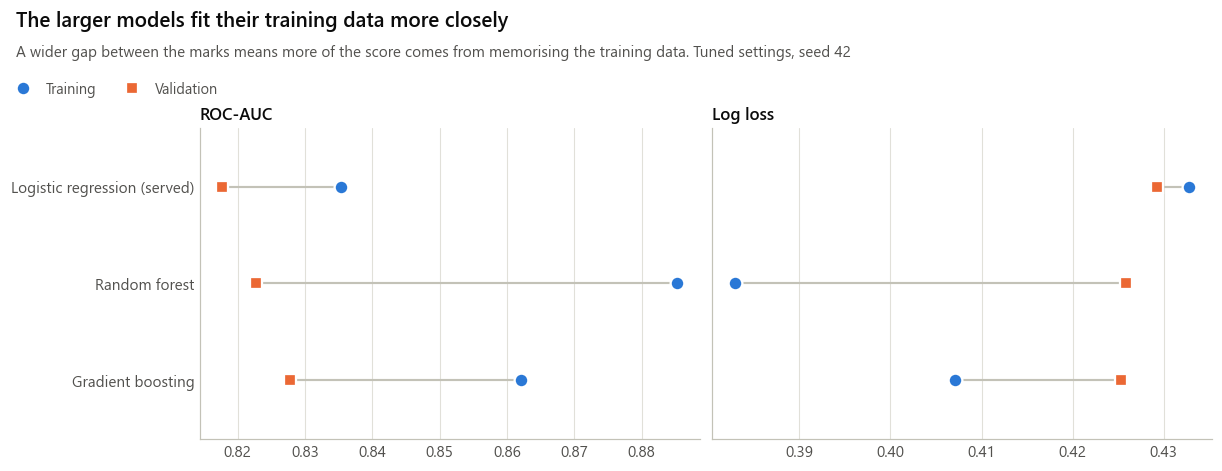

,train_auc,validation_auc,train_log_loss,validation_log_loss,size_weights_or_tree_nodes,auc_gap,log_loss_gap
model,,,,,,,
Logistic regression (served),0.835,0.818,0.433,0.429,4,0.018,-0.004
Random forest,0.885,0.823,0.383,0.426,23672,0.063,0.043
Gradient boosting,0.862,0.828,0.407,0.425,600,0.034,0.018


In [23]:
def node_count(name):
    model = fitted[name].model
    if name == "random_forest":
        return sum(tree.tree_.node_count for tree in model.estimators_)
    return sum(tree.tree_.node_count for stage in model.estimators_ for tree in stage)


rows = []
for name, (title, _, _) in ALGORITHMS.items():
    scores = pairs[name].to_numpy()
    rows.append({
        "model": title, "train_auc": auc(y[in_train], scores[in_train]), "validation_auc": auc(y[in_validation], scores[in_validation]),
        "train_log_loss": loss_of(y[in_train], scores[in_train]), "validation_log_loss": loss_of(y[in_validation], scores[in_validation]),
        "size_weights_or_tree_nodes": 4 if name == "hybrid" else node_count(name),
    })
fit_table = pd.DataFrame(rows).set_index("model")
fit_table["auc_gap"] = fit_table.train_auc - fit_table.validation_auc
fit_table["log_loss_gap"] = fit_table.validation_log_loss - fit_table.train_log_loss

figure, axes = plt.subplots(1, 2, figsize=(11, 3.3), layout="constrained", sharey=True)
positions = np.arange(len(fit_table))[::-1]
for axis, (train_column, validation_column, title, digits) in zip(axes, (("train_auc", "validation_auc", "ROC-AUC", 3), ("train_log_loss", "validation_log_loss", "Log loss", 3))):
    for position, (_, row) in zip(positions, fit_table.iterrows()):
        axis.plot([row[train_column], row[validation_column]], [position, position], color=AXIS, linewidth=1.4, zorder=1)
    axis.plot(fit_table[train_column], positions, "o", color=TRAIN_COLOUR, markersize=9, markeredgecolor=SURFACE, markeredgewidth=1.5, zorder=3, label="Training")
    axis.plot(fit_table[validation_column], positions, "s", color=VALIDATION_COLOUR, markersize=8, markeredgecolor=SURFACE, markeredgewidth=1.5, zorder=3, label="Validation")
    axis.set_yticks(positions, fit_table.index)
    axis.set_ylim(-0.6, len(fit_table) - 0.4)
    axis.set_title(title)
    axis.grid(True, axis="x")
    axis.set_axisbelow(True)
top_legend(figure, columns=2)
headed(figure, "The larger models fit their training data more closely", "A wider gap between the marks means more of the score comes from memorising the training data. Tuned settings, seed 42")
show(figure, "20_overfitting_by_algorithm")
display(fit_table.round(3))

### Figure 21. How to read ROC-AUC

**ROC-AUC answers one question: if you pick one good match and one non-match at random, how often does the model score the good match higher?** The cell below checks this directly on the warm test by comparing every good match with every non-match, and it gives the same 0.807 as the area under the curve. So 0.50 means no better than a coin toss, and 1.00 means every good match outranks every non-match.

**Reading the curve.** Each point is one threshold. Lowering it accepts more pairs, which moves you up (more good matches accepted) and to the right (more non-matches accepted too). A curve bulging towards the top-left corner means many good matches can be accepted before many non-matches get through.

**What it does not tell you.** It says nothing about the threshold actually in use. This model has 0.807 ROC-AUC and still wrongly accepts 58% of warm non-matches at 0.46, so report it alongside the confusion matrix (Figure 9).

287 good matches x 113 non-matches = 32,431 contests
Good match scored higher in 26,178 of them: 0.807. ROC-AUC from the curve: 0.807


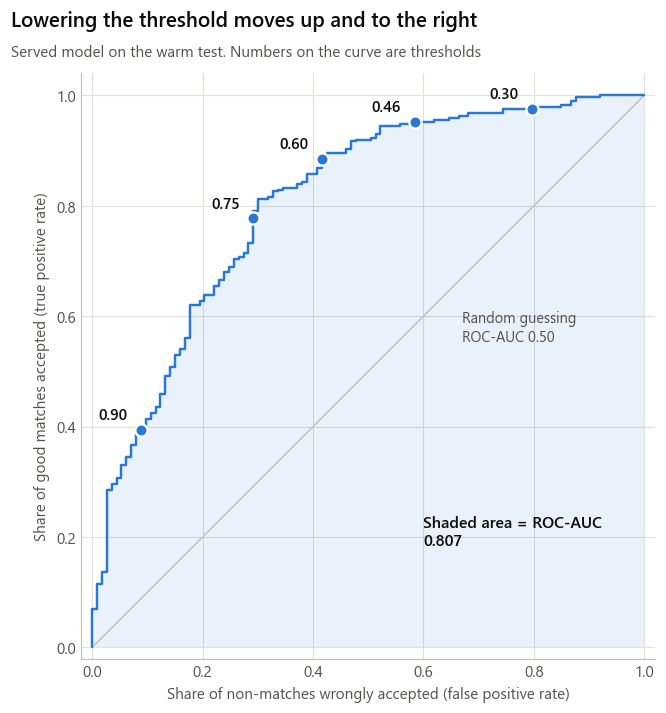

,threshold,good matches accepted (TPR),non-matches accepted (FPR),good accepted,non-matches accepted
0,0.90,0.394,0.088,113,10
1,0.75,0.777,0.292,223,33
2,0.60,0.885,0.416,254,47
3,0.46,0.951,0.584,273,66
4,0.30,0.976,0.796,280,90


In [24]:
warm = pairs[pairs.split == "warm_test"]
good = warm.loc[warm.label == 1, "hybrid"].to_numpy()
weak = warm.loc[warm.label == 0, "hybrid"].to_numpy()
wins = int((good[:, None] > weak).sum())
ties = int((good[:, None] == weak).sum())
contests = len(good) * len(weak)
print(f"{len(good)} good matches x {len(weak)} non-matches = {contests:,} contests")
print(f"Good match scored higher in {wins:,} of them: {(wins + ties / 2) / contests:.3f}. ROC-AUC from the curve: {auc(warm.label.to_numpy(), warm.hybrid.to_numpy()):.3f}")
assert abs((wins + ties / 2) / contests - auc(warm.label.to_numpy(), warm.hybrid.to_numpy())) < 1e-9

marks = [0.9, 0.75, 0.6, THRESHOLD, 0.3]
sweep_rows = []
for value in marks:
    result = at_threshold(warm.label, warm.hybrid, value)
    sweep_rows.append({"threshold": round(value, 2), "good matches accepted (TPR)": result["recall"], "non-matches accepted (FPR)": 1 - result["specificity"], "good accepted": result["tp"], "non-matches accepted": result["fp"]})
sweep_table = pd.DataFrame(sweep_rows)

figure, axis = plt.subplots(figsize=(6.6, 5.8), layout="constrained")
fpr, tpr, _ = roc_curve(warm.label, warm.hybrid)
axis.fill_between(fpr, tpr, color=BLUE, alpha=0.1, linewidth=0)
axis.plot([0, 1], [0, 1], color=AXIS, linewidth=1)
axis.plot(fpr, tpr, color=BLUE)
for _, row in sweep_table.iterrows():
    x, y_value = row["non-matches accepted (FPR)"], row["good matches accepted (TPR)"]
    axis.plot(x, y_value, "o", color=BLUE, markersize=8, markeredgecolor=SURFACE, markeredgewidth=1.5, zorder=4)
    axis.annotate(f"{row['threshold']:.2f}", (x, y_value), xytext=(-9, 7), textcoords="offset points", ha="right", color=INK, fontsize=10, fontweight="semibold")
axis.text(0.67, 0.61, "Random guessing\nROC-AUC 0.50", color=INK_2, fontsize=9.5, va="top")
axis.text(0.60, 0.24, f"Shaded area = ROC-AUC\n{auc(warm.label.to_numpy(), warm.hybrid.to_numpy()):.3f}", color=INK, fontsize=10.5, fontweight="semibold", va="top")
axis.set_xlabel("Share of non-matches wrongly accepted (false positive rate)")
axis.set_ylabel("Share of good matches accepted (true positive rate)")
axis.set_xlim(-0.02, 1.02)
axis.set_ylim(-0.02, 1.04)
axis.set_aspect("equal")
axis.grid(True)
axis.set_axisbelow(True)
headed(figure, "Lowering the threshold moves up and to the right", "Served model on the warm test. Numbers on the curve are thresholds")
show(figure, "21_how_to_read_roc")
display(sweep_table.round(3))

---
# Part 5. Why the cold test scored higher than the warm test

The served model scored ROC-AUC 0.847 on the cold test (unseen jobs) and 0.807 on the warm test (known jobs). Unseen jobs would normally be expected to score lower, so this part checks whether the gap is real. It repeats the checks in section 11 of `docs/Explanations.md`, on both synthetic populations:

1. **Random groupings.** Keep the same test candidates, but shuffle which of them count as warm or cold, keeping the number in each group. Repeat 5,000 times. If gaps as big as the real one are common, the real gap is ordinary.
2. **Share of good matches.** An easier mix of labels could inflate one test.
3. **Input gaps by label.** How far apart good and poor matches sit on each input, in each test.
4. **ROC-AUC by role.** Whether one role drives the gap.
5. **Leave one cold job out.** Whether a single unusual job explains it.

Candidates are shuffled as whole units, because one candidate's pairs are not independent of each other. No test candidate appears in both tests.

### Figure 22. The warm and cold gap against random groupings

**Most likely chance.** On the training population the gap is +0.040 and about 31% of random groupings give a gap at least that big. On the fresh population the gap flips to -0.050, with warm higher, and about 14% of groupings are that big. Neither is unusual, and they point in opposite directions.

**The label mix is not the cause.** Good matches are 71.8% of the warm test and 71.5% of the cold test on the training population.

**No single job explains it.** Leaving out each cold job in turn keeps cold ROC-AUC between 0.839 and 0.858.

**The by-role swings disagree.** DevOps Engineer is much higher cold (0.892 against 0.701) while Business Analyst and Data Analyst are higher warm, and DevOps does not repeat on the fresh population. Each role has only 9 to 28 poor matches per test, so a few pairs move these numbers a lot.

**Why cold does not have to be lower.** The model never sees which job it is scoring, only three numbers per pair, so it has nothing job-specific to memorise. Warm and cold should score about the same with random differences either way, which is what the two populations show. This does not prove they are equal: with tests this small a real difference of a few points could go undetected.

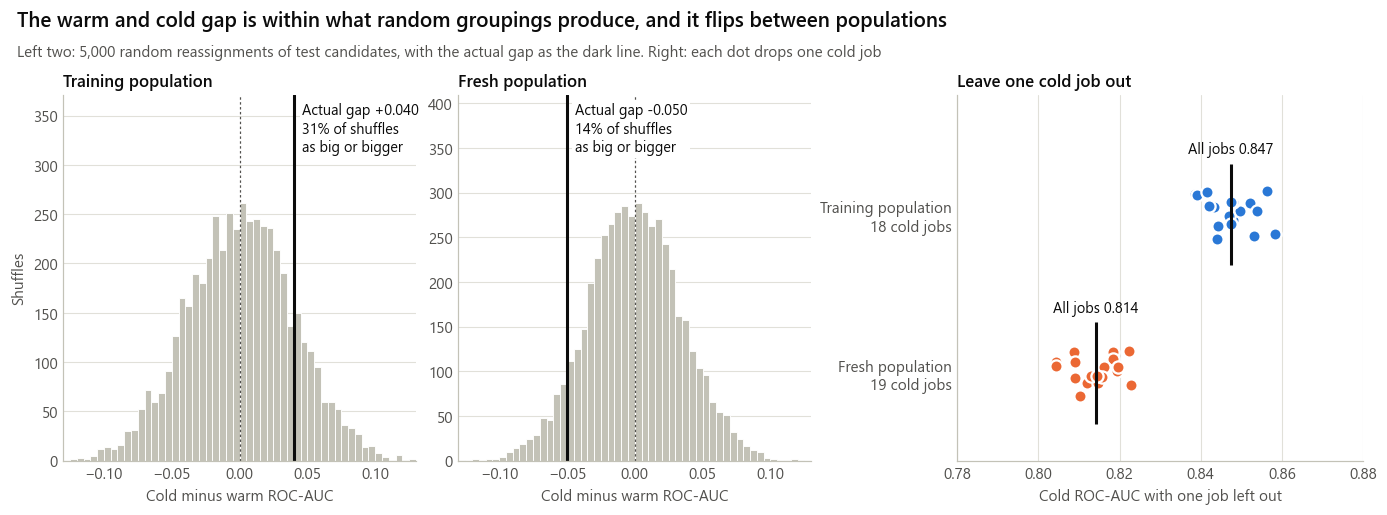

population,Training population,Fresh population
warm_roc_auc,0.807,0.864
cold_roc_auc,0.847,0.814
gap_cold_minus_warm,0.040,-0.050
random_95_low,-0.075,-0.068
random_95_high,0.078,0.068
share_of_shuffles_as_big,0.308,0.142
warm_good_match_rate,0.718,0.662
cold_good_match_rate,0.715,0.717
cold_jobs,18.000,19.000
cold_leave_one_job_out_low,0.839,0.804


How far apart good and poor matches sit on each input (good mean minus poor mean)


Semantic similarity  Related-skill overlap  \
population          test                                               
Training population Warm                0.052                  0.064   
                    Cold                0.092                  0.087   
Fresh population    Warm                0.079                  0.063   
                    Cold                0.081                  0.068   

                          Experience readiness  
population          test                        
Training population Warm                 0.309  
                    Cold                 0.233  
Fresh population    Warm                 0.359  
                    Cold                 0.228

ROC-AUC by role


poor_matches                                  \
population        Fresh population       Training population         
test                          Cold  Warm                Cold  Warm   
role                                                                 
Accountant                    13.0  21.0                 9.0  19.0   
Business Analyst              23.0  21.0                12.0  21.0   
Data Analyst                   5.0  37.0                22.0  26.0   
DevOps Engineer               30.0  26.0                18.0  28.0   
Software Engineer             18.0  30.0                24.0  19.0   

                           roc_auc                                    
population        Fresh population        Training population         
test                          Cold   Warm                Cold   Warm  
role                                                                  
Accountant                   0.730  0.866               0.830  0.806  
Business Analyst             0.830  0.888               0.704  0.859  
Data Analyst                 0.813  0.805               0.807  0.880  
DevOps Engineer              0.828  0.853               0.892  0.701  
Software Engineer            0.815  0.920               0.923  0.883

In [25]:
SHUFFLES = 5_000
populations = {"Training population": TRAINING_SEED, "Fresh population": FRESH_SEED}
POPULATION_COLOURS = {"Training population": BLUE, "Fresh population": ORANGE}


def auc_of(part):
    return auc(part.label.to_numpy(), part.hybrid.to_numpy())


def shuffled_gaps(tested, seed):
    """Cold minus warm ROC-AUC after reassigning whole candidates to the two groups, keeping group sizes."""
    rows_by_candidate = tested.groupby("candidate_id").indices
    candidate_ids = tested.candidate_id.unique()
    cold_size = tested.loc[tested.split == "cold_test", "candidate_id"].nunique()
    labels, scores = tested.label.to_numpy(), tested.hybrid.to_numpy()
    rng = np.random.default_rng(seed)
    gaps = np.empty(SHUFFLES)
    for index in range(SHUFFLES):
        order = rng.permutation(candidate_ids)
        cold = np.concatenate([rows_by_candidate[key] for key in order[:cold_size]])
        warm = np.concatenate([rows_by_candidate[key] for key in order[cold_size:]])
        gaps[index] = auc(labels[cold], scores[cold]) - auc(labels[warm], scores[warm])
    return gaps


checks, gap_samples, leave_one_out, input_rows, role_rows = [], {}, {}, [], []
for population, seed in populations.items():
    frame, _, _ = load_pairs(seed, CONTRACT_V2)
    frame["hybrid"] = sigmoid_score(model_v2, frame[list(FEATURES)].to_numpy())
    tested = frame[frame.split.isin(TEST_SPLITS)].reset_index(drop=True)
    assert tested.groupby("candidate_id").split.nunique().max() == 1, "a test candidate appears in both tests"
    warm, cold = (tested[tested.split == split] for split in TEST_SPLITS)
    gap = auc_of(cold) - auc_of(warm)
    gaps = shuffled_gaps(tested, seed)
    gap_samples[population] = (gap, gaps)
    leave_one_out[population] = pd.Series({job: auc_of(cold[cold.job_id != job]) for job in cold.job_id.unique()})
    low, high = np.percentile(gaps, [2.5, 97.5])
    checks.append({
        "population": population, "warm_roc_auc": auc_of(warm), "cold_roc_auc": auc_of(cold), "gap_cold_minus_warm": gap,
        "random_95_low": low, "random_95_high": high, "share_of_shuffles_as_big": float(np.mean(np.abs(gaps) >= abs(gap))),
        "warm_good_match_rate": warm.label.mean(), "cold_good_match_rate": cold.label.mean(),
        "cold_jobs": cold.job_id.nunique(), "cold_leave_one_job_out_low": leave_one_out[population].min(), "cold_leave_one_job_out_high": leave_one_out[population].max(),
    })
    for split, part in (("Warm", warm), ("Cold", cold)):
        good, poor = part[part.label == 1], part[part.label == 0]
        input_rows.append({"population": population, "test": split, **{FEATURES[name].split(" (")[0]: good[name].mean() - poor[name].mean() for name in FEATURES}})
        for role, group in part.groupby("role"):
            role_rows.append({"population": population, "role": role, "test": split, "roc_auc": auc_of(group), "poor_matches": int((group.label == 0).sum())})
checks = pd.DataFrame(checks).set_index("population")

# The values reported in docs/Explanations.md section 11. Stop if a re-run disagrees.
training, fresh = checks.loc["Training population"], checks.loc["Fresh population"]
assert round(training.gap_cold_minus_warm, 3) == 0.040 and round(fresh.gap_cold_minus_warm, 3) == -0.050
assert round(training.share_of_shuffles_as_big, 2) == 0.31 and round(fresh.share_of_shuffles_as_big, 2) == 0.14
assert (round(training.cold_leave_one_job_out_low, 3), round(training.cold_leave_one_job_out_high, 3)) == (0.839, 0.858)

figure = plt.figure(figsize=(12.5, 4.0), layout="constrained")
grid = figure.add_gridspec(1, 3, width_ratios=[1, 1, 1.15])
edges = np.linspace(-0.13, 0.13, 53)
for index, (population, (gap, gaps)) in enumerate(gap_samples.items()):
    axis = figure.add_subplot(grid[index])
    heights, _, _ = axis.hist(gaps, bins=edges, color=AXIS, edgecolor=SURFACE, linewidth=0.6)
    axis.set_ylim(0, heights.max() * 1.42)
    axis.axvline(0, color=INK_2, linewidth=0.8, linestyle=(0, (2, 2)))
    axis.axvline(gap, color=INK, linewidth=2)
    share = checks.loc[population, "share_of_shuffles_as_big"]
    axis.text(gap + 0.006, axis.get_ylim()[1] * 0.98, f"Actual gap {gap:+.3f}\n{share:.0%} of shuffles\nas big or bigger", ha="left", va="top", color=INK, fontsize=9.5, bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1.5), zorder=5)
    axis.set_title(population)
    axis.set_xlabel("Cold minus warm ROC-AUC")
    axis.set_ylabel("Shuffles" if index == 0 else "")
    axis.set_xlim(edges[0], edges[-1])
    bar_grid(axis, "y")
axis = figure.add_subplot(grid[2])
for position, (population, values) in zip((1, 0), leave_one_out.items()):
    colour = POPULATION_COLOURS[population]
    jitter = np.random.default_rng(len(values)).uniform(-0.16, 0.16, len(values))
    axis.plot(values.to_numpy(), position + jitter, "o", color=colour, markersize=8, markeredgecolor=SURFACE, markeredgewidth=1.5, linestyle="none", label=population)
    full = checks.loc[population, "cold_roc_auc"]
    axis.vlines(full, position - 0.32, position + 0.32, color=INK, linewidth=2)
    axis.text(full, position + 0.36, f"All jobs {full:.3f}", ha="center", va="bottom", color=INK, fontsize=9.5)
axis.set_yticks([1, 0], [f"{name}\n{len(values)} cold jobs" for name, values in leave_one_out.items()])
axis.set_ylim(-0.55, 1.75)
axis.set_xlim(0.78, 0.88)
axis.set_xlabel("Cold ROC-AUC with one job left out")
axis.set_title("Leave one cold job out")
bar_grid(axis, "x")
headed(figure, "The warm and cold gap is within what random groupings produce, and it flips between populations", f"Left two: {SHUFFLES:,} random reassignments of test candidates, with the actual gap as the dark line. Right: each dot drops one cold job")
show(figure, "22_warm_cold_gap_checks")
checks.to_csv(FIGURES / "warm_cold_checks.csv")
display(checks.T.round(3))
print("How far apart good and poor matches sit on each input (good mean minus poor mean)")
display(pd.DataFrame(input_rows).set_index(["population", "test"]).round(3))
print("ROC-AUC by role")
display(pd.DataFrame(role_rows).pivot_table(index="role", columns=["population", "test"], values=["roc_auc", "poor_matches"]).round(3))

---
# Still missing: human-labelled evidence

All the figures above score the model against labels from the same generator. The gold slice is the planned independent check: 150 pairs for a person to judge without seeing any score. Until it is labelled, there is no evidence of agreement with human judgement, so no figure can be made for it.

In [26]:
sheet = ROOT / "data_pipeline" / "gold_slice" / "gold-seed20261015-150pairs" / "labelling_sheet.csv"
with sheet.open(encoding="utf-8") as handle:
    rows = list(csv.DictReader(handle))
print(f"Gold slice: {sum(bool(row['label'].strip()) for row in rows)} of {len(rows)} pairs labelled by a person")

Gold slice: 0 of 150 pairs labelled by a person


---
# Summary for the report

| Question | Answer | Figure |
|---|---|---|
| Is the data balanced? | Roles yes. Labels no: about 73% good matches | 1, 2 |
| Did it overfit? | No sign of it: train and validation stay close across all 100 epochs | 6, 7 |
| Did training need 100 epochs? | No. Loss settles in the first epoch; epoch 4 is the lowest point of later noise | 6 |
| How well does it rank? | ROC-AUC 0.807 warm, 0.847 cold; top pick good 93% of the time against 71% at random | 11, 16 |
| How good is the yes/no decision? | Recall 95-99%, specificity only 31-42%; accuracy 80% against 72% for always yes | 9 |
| Better than semantic similarity alone? | Yes, clearly | 10, 11 |
| Better than hand-set fixed weights? | Not shown: differences are within noise. Its scores are calibrated probabilities | 10, 13 |
| Are scores trustworthy as probabilities? | Reasonably at the high end, noisier in the middle | 13 |
| Why did unseen jobs score higher than known jobs? | Most likely chance: the gap is within random groupings and flips on a fresh population | 22 |
| Is logistic regression the most accurate algorithm? | No. Gradient boosting and random forest rank slightly better on the same inputs, with the same F1. The simple model's case is that it is explainable | 19, 20 |
| Does it match human judgement? | **Unknown.** Gold slice: 0 of 150 labelled | Last cell |

**Safe to claim:** on seeded synthetic data with leakage-controlled splits, the three-feature model ranks well above random and above semantic similarity alone, shows no overfitting, and gives reasonably calibrated scores.

**Not safe to claim:** that it predicts real hiring outcomes, that it beats the fixed weights, that logistic regression is the most accurate algorithm tried, or that it rejects weak candidates reliably.

The older `overfitting_diagnostics.png` and `test_evaluation.png` in `data_pipeline/reports/` date from September, before this model. Use the figures here instead.